# Eksplorasi dan Implementasi Python: Probabilitas & Distribusi Probabilitas
**M. Arief · 2455301093 · 3 TI C · Probabilitas dan Statistika · Politeknik Caltex Riau**

Cara pakai: menu **Runtime → Run all**. Untuk Soal 2.10 dan 3.8, upload dulu file
`3TIC_04_PerformaQUICvsHTTP2.xlsx` ke panel Files (ikon folder di kiri).

In [1]:
# ===== SETUP: import library, seed, dan fungsi tampilan sendiri =====
import math, random, itertools, statistics, sys
from fractions import Fraction
from collections import Counter
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

SEED = 2455301093          # NIM -> hasil simulasi selalu sama tiap dijalankan
N_SIM = 100_000            # banyak percobaan untuk simulasi
REKAP = []                 # menampung semua hasil untuk tabel rekap di akhir

%config InlineBackend.figure_format = "retina"   # gambar grafik lebih tajam
plt.rcParams.update({"figure.figsize": (7.5, 3.6), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BIRU, ORANYE, MERAH = "#1f4e79", "#f28e2b", "#c0392b"

def kotak_hasil(judul, baris, catatan=None):
    """baris = [(besaran, manual, python, simulasi atau None), ...]
    Cocok jika |manual - python| < 0.001 (pembulatan tabel) dan simulasi dekat:
    selisih <= 0.01 untuk peluang, <= 2% untuk nilai > 1 (E dan Var)."""
    L = 69
    angka = lambda v: "-" if v is None else (f"{v:.4f}" if abs(v) < 100 else f"{v:.2f}")
    print("╔" + f"══ {judul} ".ljust(L, "═") + "╗")
    print("║ " + f"{'Besaran':<24}{'Manual':>10}{'Python':>10}{'Simulasi':>10}  {'Status':<11}" + " ║")
    print("╟" + "─" * L + "╢")
    for besaran, m, p, s in baris:
        sama = abs(m - p) < 1e-3 * max(1, abs(p))
        dekat = s is None or abs(s - p) <= (0.01 if abs(p) <= 1 else 0.02 * abs(p))
        status = "✓ cocok" if sama and dekat else "✗ periksa"
        print("║ " + f"{besaran:<24}{angka(m):>10}{angka(p):>10}{angka(s):>10}  {status:<11}" + " ║")
        REKAP.append({"soal": judul.split(" ·")[0], "besaran": besaran, "manual": m,
                      "python": float(p), "simulasi": s, "status": status})
    print("╚" + "═" * L + "╝")
    if catatan:
        print("→", catatan)

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | pandas 3.0.5 | Matplotlib 3.11.2


## 1 · Eksplorasi Library
Satu contoh singkat untuk tiap library yang dipakai.

In [2]:
# ===== DEMO SINGKAT: 1 contoh untuk tiap library =====
rng = np.random.default_rng(SEED)
print("math        →", "C(5,2) =", math.comb(5, 2), "| P(5,2) =", math.perm(5, 2), "| 4! =", math.factorial(4))
print("fractions   →", Fraction(3, 12), "+", Fraction(1, 6), "=", Fraction(3, 12) + Fraction(1, 6))
print("itertools   →", list(itertools.combinations("ABC", 2)))
print("collections →", Counter(["H2", "H3", "H3", "H2", "H3"]))
print("random      →", random.Random(SEED).choice(["sukses", "gagal"]))
print("statistics  →", round(statistics.NormalDist(mu=0, sigma=1).cdf(1.96), 4), "= P(Z < 1.96)")
print("numpy       →", rng.integers(1, 7, size=6), "(6 lemparan dadu)")
print("scipy.stats →", round(stats.binom.pmf(k=3, n=10, p=0.5), 4), "= P(3 sukses dari 10 percobaan)")
print("pandas      →", pd.Series(["ok", "ok", "gagal", "ok"]).value_counts().to_dict())
print("matplotlib  → versi", matplotlib.__version__, "(dipakai untuk semua grafik)")

math        → C(5,2) = 10 | P(5,2) = 20 | 4! = 24
fractions   → 1/4 + 1/6 = 5/12
itertools   → [('A', 'B'), ('A', 'C'), ('B', 'C')]
collections → Counter({'H3': 3, 'H2': 2})
random      → sukses
statistics  → 0.975 = P(Z < 1.96)
numpy       → [6 3 5 4 3 1] (6 lemparan dadu)
scipy.stats → 0.1172 = P(3 sukses dari 10 percobaan)
pandas      → {'ok': 3, 'gagal': 1}
matplotlib  → versi 3.11.2 (dipakai untuk semua grafik)


## 2 · Implementasi Permasalahan Probabilitas

**Soal 2.1** Kode OTP 6 digit (000000–999999) dibuat acak. Berapa peluang keenam digitnya berbeda semua?

*Function:* `math.perm`, `itertools.product`, `Fraction`, `random.Random().choices`

In [3]:
# ===== SOAL 2.1 · OTP 6 digit, semua digit berbeda =====
# Ruang sampel: semua kode 000000-999999 (10^6). Kejadian A: keenam digit berbeda.
manual = (10 * 9 * 8 * 7 * 6 * 5) / 10**6            # aturan perkalian

p_rumus = math.perm(10, 6) / 10**6                   # Python cara 1: rumus permutasi
n_S, n_A = 0, 0                                      # cara 2: cek SEMUA kode satu per satu
for kode in itertools.product(range(10), repeat=6):
    n_S += 1
    n_A += len(set(kode)) == 6
p_enum = Fraction(n_A, n_S)
print(f"n(S) = {n_S}, n(A) = {n_A}, P(A) = {p_enum} = {float(p_enum)}")

acak = random.Random(SEED)                           # simulasi pakai library random bawaan
sukses = sum(len(set(acak.choices(range(10), k=6))) == 6 for _ in range(N_SIM))

kotak_hasil("SOAL 2.1 · OTP 6 digit berbeda",
            [("P(semua digit beda)", manual, p_rumus, sukses / N_SIM)],
            catatan="Hanya ±15% OTP acak yang keenam digitnya berbeda; sisanya punya digit kembar.")

n(S) = 1000000, n(A) = 151200, P(A) = 189/1250 = 0.1512
╔══ SOAL 2.1 · OTP 6 digit berbeda ═══════════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(semua digit beda)         0.1512    0.1512    0.1508  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ Hanya ±15% OTP acak yang keenam digitnya berbeda; sisanya punya digit kembar.


**Soal 2.2** Tim proyek 3 orang dipilih acak dari 5 developer backend dan 4 frontend. Berapa peluang tim berisi minimal 1 frontend? Berapa peluang tepat 2 frontend?

*Function:* `math.comb`, `itertools.combinations`, `Counter`, `np.random.default_rng`, `argsort`, `plt.bar`

Banyak tim = 84 | tim per jumlah frontend: {0: 10, 1: 40, 2: 30, 3: 4}
╔══ SOAL 2.2 · Tim proyek (kombinasi) ════════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(minimal 1 frontend)       0.8810    0.8810    0.8809  ✓ cocok     ║
║ P(tepat 2 frontend)         0.3571    0.3571    0.3561  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝


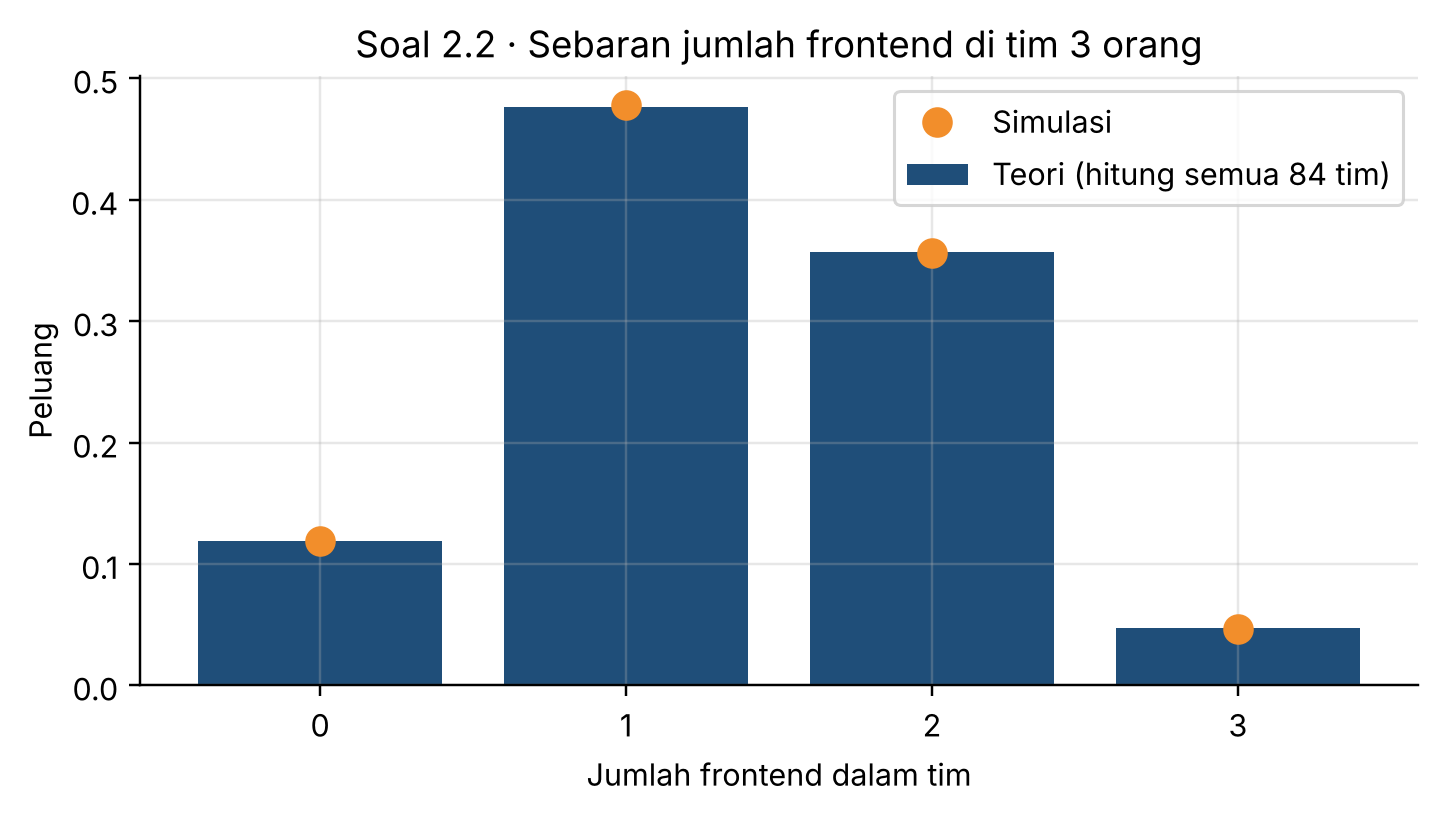

In [4]:
# ===== SOAL 2.2 · Tim proyek 3 orang dari 5 backend + 4 frontend =====
dev = ["B1", "B2", "B3", "B4", "B5", "F1", "F2", "F3", "F4"]
manual_min1 = 1 - 10 / 84                  # 1 - C(5,3)/C(9,3)  (komplemen: semua backend)
manual_tepat2 = (6 * 5) / 84               # C(4,2) x C(5,1) / C(9,3)

p_min1 = 1 - math.comb(5, 3) / math.comb(9, 3)
p_tepat2 = math.comb(4, 2) * math.comb(5, 1) / math.comb(9, 3)
semua_tim = list(itertools.combinations(dev, 3))
jml_front = Counter(sum(o.startswith("F") for o in tim) for tim in semua_tim)
print("Banyak tim =", len(semua_tim), "| tim per jumlah frontend:", dict(sorted(jml_front.items())))

rng = np.random.default_rng(SEED)
pilih = rng.random((N_SIM, 9)).argsort(axis=1)[:, :3]   # 3 orang acak, tanpa pengembalian
n_front = (pilih >= 5).sum(axis=1)                       # indeks 5-8 = frontend
kotak_hasil("SOAL 2.2 · Tim proyek (kombinasi)", [
    ("P(minimal 1 frontend)", manual_min1, p_min1, (n_front >= 1).mean()),
    ("P(tepat 2 frontend)", manual_tepat2, p_tepat2, (n_front == 2).mean())])

k = sorted(jml_front)
plt.bar(k, [jml_front[i] / 84 for i in k], color=BIRU, label="Teori (hitung semua 84 tim)")
plt.plot(k, [(n_front == i).mean() for i in k], "o", color=ORANYE, ms=9, label="Simulasi")
plt.xticks(k); plt.xlabel("Jumlah frontend dalam tim"); plt.ylabel("Peluang")
plt.title("Soal 2.2 · Sebaran jumlah frontend di tim 3 orang"); plt.legend(); plt.show()

**Soal 2.3** Dari 120 tiket helpdesk, 48 tiket masalah jaringan (J), 36 masalah software (S), dan 12 tiket kena keduanya. Berapa peluang tiket acak termasuk J atau S?

*Function:* `set` (bawaan Python), `Fraction`, `rng.integers`, `np.isin`, `plt.Circle`

n(J) = 48 | n(S) = 36 | n(J∩S) = 12 | n(J∪S) = 72
╔══ SOAL 2.3 · Aturan penjumlahan ════════════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(J ∪ S)                    0.6000    0.6000    0.5994  ✓ cocok     ║
║ P(bukan J dan bukan S)      0.4000    0.4000    0.4006  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ P(J ∪ S) = 3/5. Irisan dikurangi sekali supaya tidak terhitung dobel.


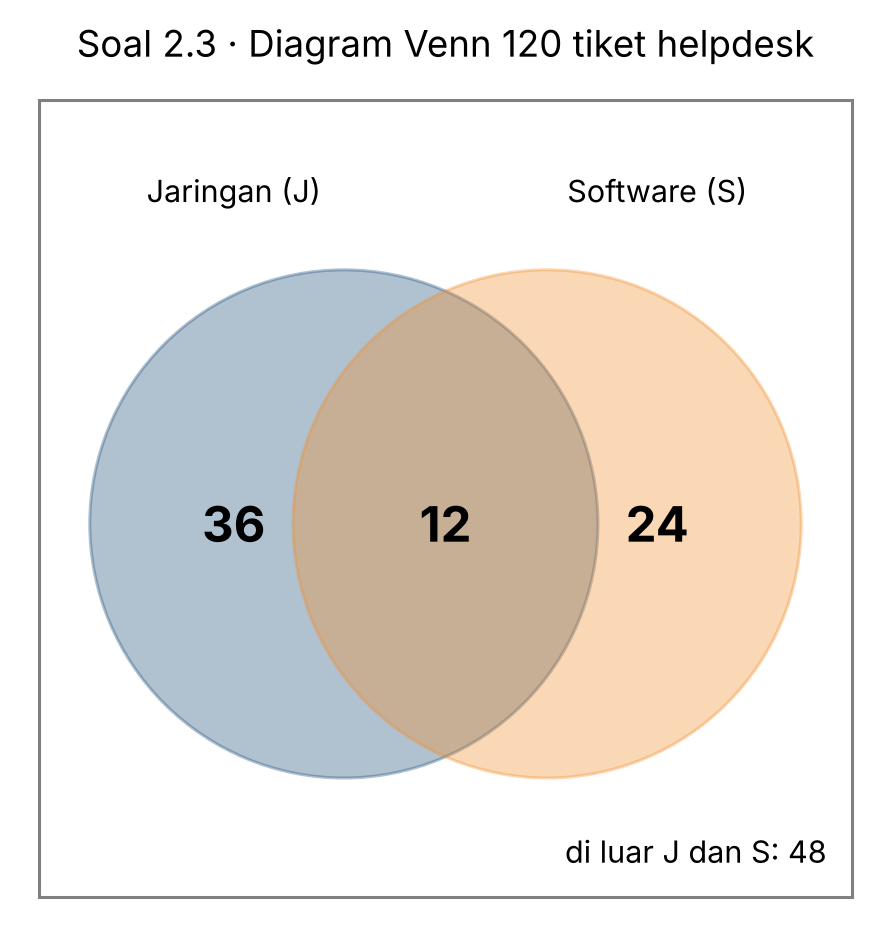

In [5]:
# ===== SOAL 2.3 · Tiket helpdesk: jaringan ATAU software =====
manual = 48/120 + 36/120 - 12/120            # P(J ∪ S) = P(J) + P(S) - P(J ∩ S)

tiket = set(range(1, 121))
J = set(range(1, 49))                        # tiket 1-48
S = set(range(37, 73))                       # tiket 37-72 -> irisan 37-48 = 12 tiket
print("n(J) =", len(J), "| n(S) =", len(S), "| n(J∩S) =", len(J & S), "| n(J∪S) =", len(J | S))
p_union = Fraction(len(J | S), len(tiket))
p_luar = Fraction(len(tiket - (J | S)), len(tiket))

rng = np.random.default_rng(SEED)
ambil = rng.integers(1, 121, N_SIM)          # ambil 1 tiket acak, ulangi N_SIM kali
sim_union = np.isin(ambil, list(J | S)).mean()
kotak_hasil("SOAL 2.3 · Aturan penjumlahan", [
    ("P(J ∪ S)", manual, float(p_union), sim_union),
    ("P(bukan J dan bukan S)", 1 - manual, float(p_luar), 1 - sim_union)],
    catatan=f"P(J ∪ S) = {p_union}. Irisan dikurangi sekali supaya tidak terhitung dobel.")

fig, ax = plt.subplots(figsize=(5.4, 5))
ax.add_patch(plt.Rectangle((0.02, 0.03), 0.96, 0.94, fill=False, color="gray"))
ax.add_patch(plt.Circle((0.38, 0.47), 0.3, color=BIRU, alpha=0.35))
ax.add_patch(plt.Circle((0.62, 0.47), 0.3, color=ORANYE, alpha=0.35))
for x, t in [(0.25, len(J - S)), (0.5, len(J & S)), (0.75, len(S - J))]:
    ax.text(x, 0.47, t, ha="center", va="center", fontsize=16, weight="bold")
ax.text(0.25, 0.85, "Jaringan (J)", ha="center"); ax.text(0.75, 0.85, "Software (S)", ha="center")
ax.text(0.95, 0.07, f"di luar J dan S: {len(tiket - (J | S))}", ha="right")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Soal 2.3 · Diagram Venn 120 tiket helpdesk"); plt.show()

**Soal 2.4** Dua server (A dan B) masing-masing aktif dengan peluang 0,95 dan saling bebas. Bandingkan peluang sistem aktif bila disusun seri (butuh keduanya) dan paralel (cukup salah satu).

*Function:* `rng.random`, `.all()`, `.any()`, `plt.plot`

╔══ SOAL 2.4 · Server seri vs paralel ════════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(sistem seri aktif)        0.9025    0.9025    0.9015  ✓ cocok     ║
║ P(sistem paralel aktif)     0.9975    0.9975    0.9976  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
Perkiraan mati per tahun → seri: 854 jam | paralel: 21.9 jam


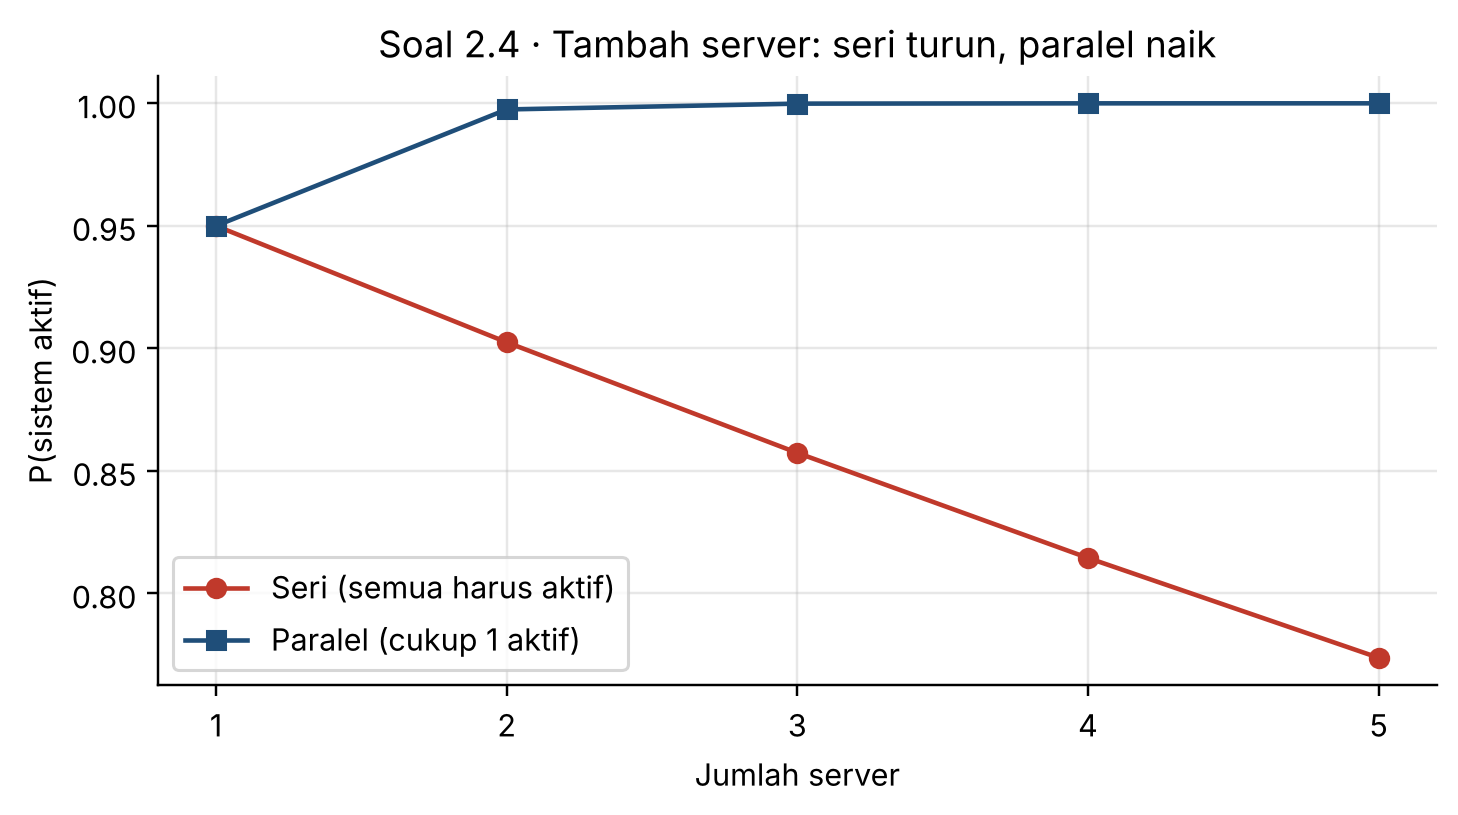

In [6]:
# ===== SOAL 2.4 · Keandalan server: seri vs paralel (kejadian saling bebas) =====
p = 0.95                                     # peluang 1 server sedang aktif
manual_seri = 0.95 * 0.95                   # A DAN B aktif  -> aturan perkalian
manual_paralel = 1 - 0.05 * 0.05            # minimal satu aktif = 1 - P(dua-duanya mati)

p_seri = p ** 2
p_paralel = 1 - (1 - p) ** 2
rng = np.random.default_rng(SEED)
aktif = rng.random((N_SIM, 2)) < p           # kolom 0 = server A, kolom 1 = server B
kotak_hasil("SOAL 2.4 · Server seri vs paralel", [
    ("P(sistem seri aktif)", manual_seri, p_seri, aktif.all(axis=1).mean()),
    ("P(sistem paralel aktif)", manual_paralel, p_paralel, aktif.any(axis=1).mean())])

jam = 365 * 24
print(f"Perkiraan mati per tahun → seri: {(1 - p_seri) * jam:.0f} jam | paralel: {(1 - p_paralel) * jam:.1f} jam")

n = np.arange(1, 6)
plt.plot(n, p ** n, "o-", color=MERAH, label="Seri (semua harus aktif)")
plt.plot(n, 1 - (1 - p) ** n, "s-", color=BIRU, label="Paralel (cukup 1 aktif)")
plt.xticks(n); plt.xlabel("Jumlah server"); plt.ylabel("P(sistem aktif)")
plt.title("Soal 2.4 · Tambah server: seri turun, paralel naik"); plt.legend(); plt.show()

**Soal 2.5** Data ilustrasi 400 akun: 160 memakai 2FA (4 kebobolan) dan 240 tanpa 2FA (36 kebobolan). Hitung P(kebobolan | tanpa 2FA), P(kebobolan | pakai 2FA), dan P(tanpa 2FA | kebobolan).

*Function:* `pd.DataFrame`, `pd.crosstab` (dengan `normalize`), `plt.barh`

kebobolan  Tidak  Ya  Total
pakai_2FA                  
Tidak        204  36    240
Ya           156   4    160
Total        360  40    400 

╔══ SOAL 2.5 · Probabilitas bersyarat (2FA) ══════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(K | tanpa 2FA)            0.1500    0.1500         -  ✓ cocok     ║
║ P(K | pakai 2FA)            0.0250    0.0250         -  ✓ cocok     ║
║ P(tanpa 2FA | K)            0.9000    0.9000         -  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ P(K | tanpa 2FA) ≠ P(tanpa 2FA | K): urutan syarat mengubah arti.


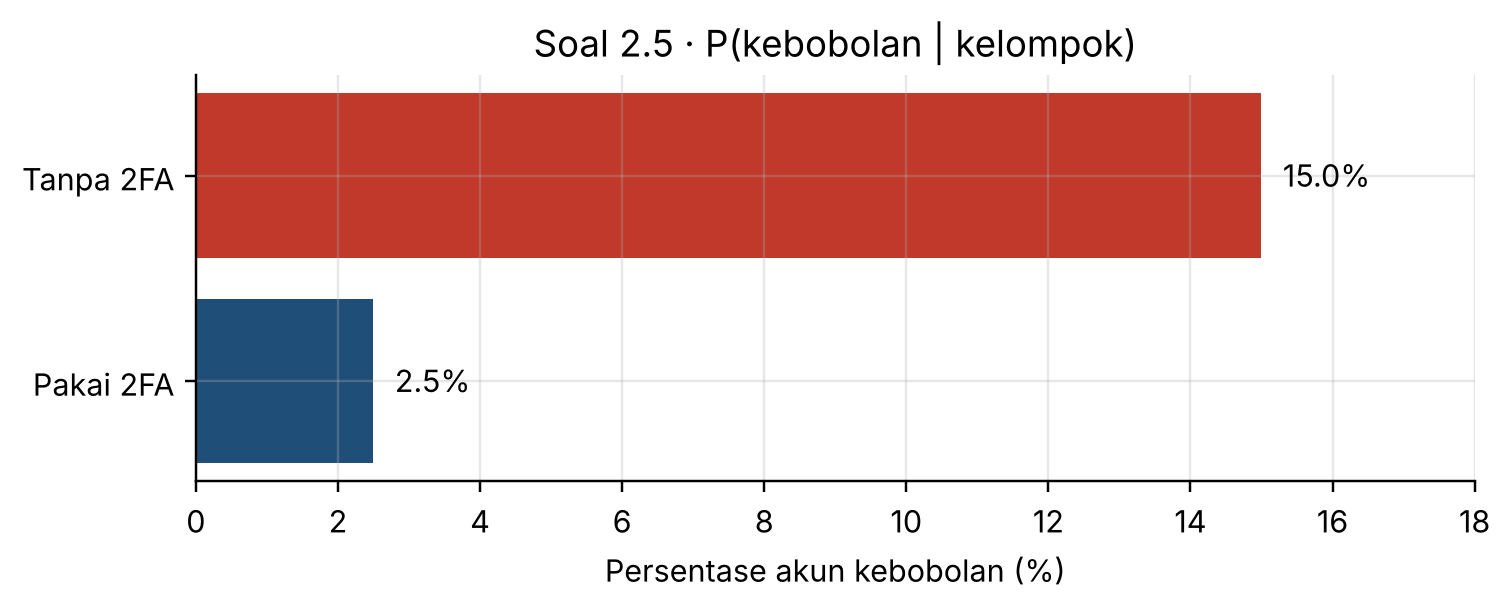

In [7]:
# ===== SOAL 2.5 · Probabilitas bersyarat: akun kebobolan (K) vs 2FA =====
akun = pd.DataFrame({
    "pakai_2FA": ["Ya"] * 160 + ["Tidak"] * 240,
    "kebobolan": ["Ya"] * 4 + ["Tidak"] * 156 + ["Ya"] * 36 + ["Tidak"] * 204})
print(pd.crosstab(akun["pakai_2FA"], akun["kebobolan"], margins=True, margins_name="Total"), "\n")

manual_tanpa = (36/400) / (240/400)          # P(K | tanpa) = P(K ∩ tanpa) / P(tanpa)
manual_dengan = (4/400) / (160/400)
manual_balik = (36/400) / (40/400)           # P(tanpa | K) = P(K ∩ tanpa) / P(K)

per_baris = pd.crosstab(akun["pakai_2FA"], akun["kebobolan"], normalize="index")
per_kolom = pd.crosstab(akun["pakai_2FA"], akun["kebobolan"], normalize="columns")
kotak_hasil("SOAL 2.5 · Probabilitas bersyarat (2FA)", [
    ("P(K | tanpa 2FA)", manual_tanpa, per_baris.loc["Tidak", "Ya"], None),
    ("P(K | pakai 2FA)", manual_dengan, per_baris.loc["Ya", "Ya"], None),
    ("P(tanpa 2FA | K)", manual_balik, per_kolom.loc["Tidak", "Ya"], None)],
    catatan="P(K | tanpa 2FA) ≠ P(tanpa 2FA | K): urutan syarat mengubah arti.")

risiko = per_baris["Ya"].sort_values()
label = risiko.index.map({"Ya": "Pakai 2FA", "Tidak": "Tanpa 2FA"})
plt.figure(figsize=(7.5, 2.4))
plt.barh(label, risiko.values * 100, color=[BIRU, MERAH])
for i, v in enumerate(risiko.values * 100):
    plt.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.xlim(0, 18); plt.xlabel("Persentase akun kebobolan (%)")
plt.title("Soal 2.5 · P(kebobolan | kelompok)"); plt.show()

**Soal 2.6** 20% email adalah spam. Filter menandai spam dengan benar 95%, tetapi juga salah menandai 3% email aman. Jika sebuah email tertandai spam, berapa peluang email itu benar-benar spam?

*Function:* fungsi `bayes()` buatan sendiri, `rng.random`, `np.where`, `plt.barh`

╔══ SOAL 2.6 · Bayes filter spam ═════════════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(T) total                  0.2140    0.2140    0.2145  ✓ cocok     ║
║ P(spam | tertanda)          0.8879    0.8879    0.8866  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ Dari 100 email tertandai, ±89 benar spam dan ±11 email aman ikut tertandai.


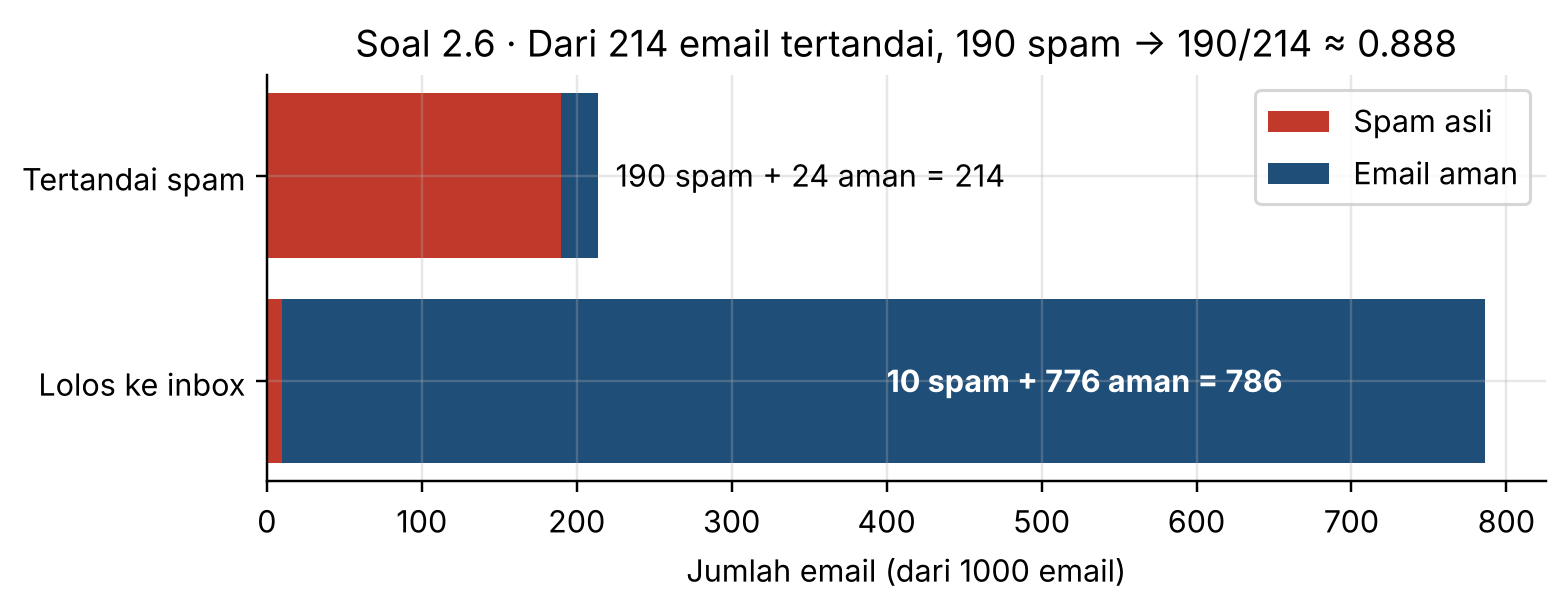

In [8]:
# ===== SOAL 2.6 · Teorema Bayes: filter spam =====
p_spam = 0.20            # P(S)
p_t_spam = 0.95          # P(T | S): spam tertandai
p_t_aman = 0.03          # P(T | bukan S): email aman ikut tertandai
# Manual: P(T) = 0.95(0.20) + 0.03(0.80) = 0.214  ->  P(S | T) = 0.19 / 0.214
manual = 0.19 / 0.214

def bayes(prior, p_jika_benar, p_jika_salah):
    total = p_jika_benar * prior + p_jika_salah * (1 - prior)    # probabilitas total
    return p_jika_benar * prior / total

rng = np.random.default_rng(SEED)
spam = rng.random(N_SIM) < p_spam
tertanda = np.where(spam, rng.random(N_SIM) < p_t_spam, rng.random(N_SIM) < p_t_aman)
kotak_hasil("SOAL 2.6 · Bayes filter spam", [
    ("P(T) total", 0.214, p_t_spam * p_spam + p_t_aman * (1 - p_spam), tertanda.mean()),
    ("P(spam | tertanda)", manual, bayes(p_spam, p_t_spam, p_t_aman), spam[tertanda].mean())],
    catatan="Dari 100 email tertandai, ±89 benar spam dan ±11 email aman ikut tertandai.")

fig, ax = plt.subplots(figsize=(7.5, 2.4))
y = ["Lolos ke inbox", "Tertandai spam"]
ax.barh(y, [10, 190], color=MERAH, label="Spam asli")
ax.barh(y, [776, 24], left=[10, 190], color=BIRU, label="Email aman")
ax.text(225, 1, "190 spam + 24 aman = 214", va="center")
ax.text(400, 0, "10 spam + 776 aman = 786", va="center", color="white", weight="bold")
ax.set_xlabel("Jumlah email (dari 1000 email)"); ax.legend(loc="upper right")
ax.set_title("Soal 2.6 · Dari 214 email tertandai, 190 spam → 190/214 ≈ 0.888"); plt.show()

**Soal 2.7** Request dilayani 3 data center: DC-A 45%, DC-B 35%, DC-C 20%. Peluang request error di tiap DC: 2%, 1%, 4%. Berapa peluang sebuah request error? Jika error, berapa peluang berasal dari DC-C?

*Function:* `np.array`, `.sum()`, `rng.choice`, `pd.DataFrame`, `plt.bar`

      P(DC)  P(E|DC)  P(DC∩E)  P(DC|E)
DC-A   0.45     0.02   0.0090   0.4390
DC-B   0.35     0.01   0.0035   0.1707
DC-C   0.20     0.04   0.0080   0.3902 



╔══ SOAL 2.7 · Probabilitas total (3 DC) ═════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(Error) total              0.0205    0.0205    0.0204  ✓ cocok     ║
║ P(DC-C | Error)             0.3902    0.3902    0.3941  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝


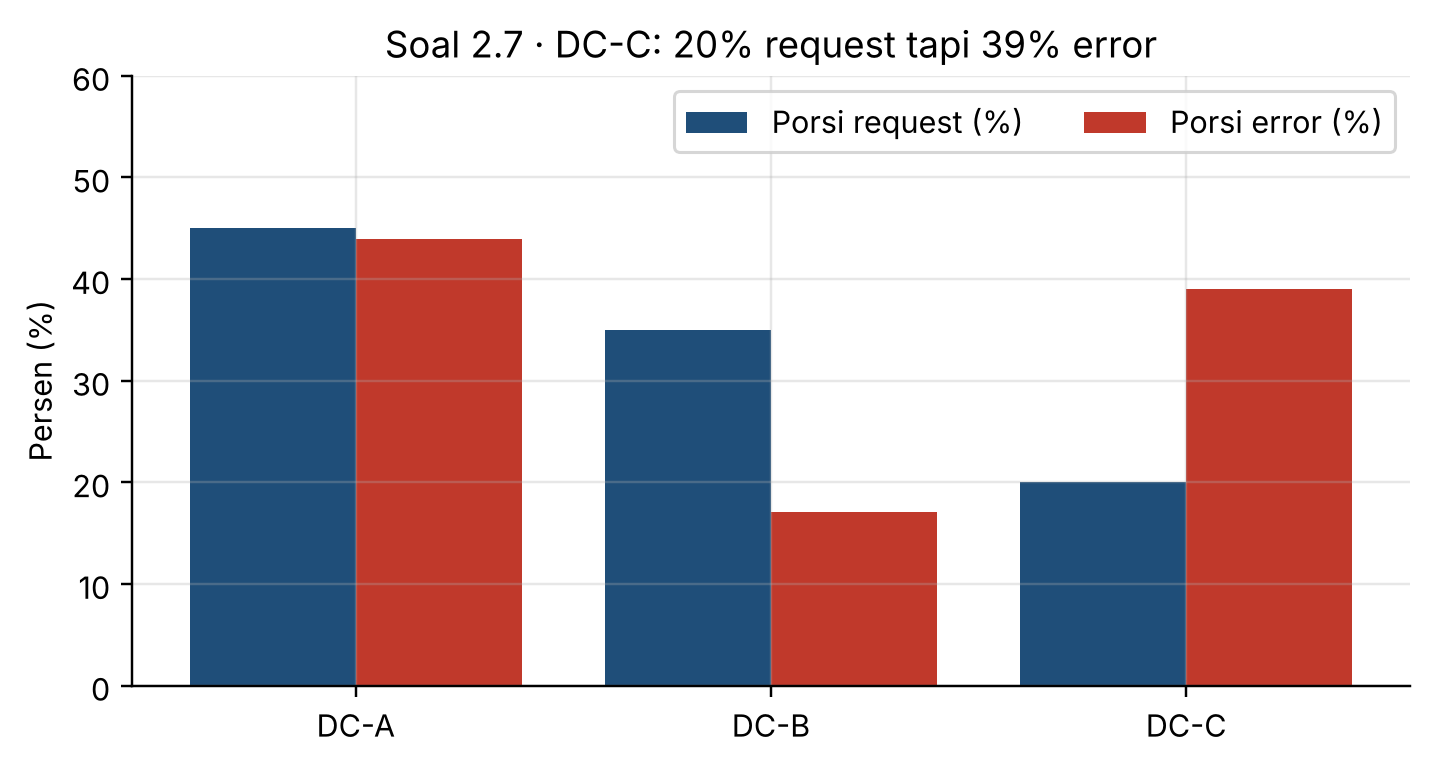

In [9]:
# ===== SOAL 2.7 · Probabilitas total + Bayes: 3 data center =====
dc = ["DC-A", "DC-B", "DC-C"]
porsi = np.array([0.45, 0.35, 0.20])     # P(DC)
p_err = np.array([0.02, 0.01, 0.04])     # P(E | DC)
manual_total = 0.45*0.02 + 0.35*0.01 + 0.20*0.04       # = 0.0205
manual_C = (0.20 * 0.04) / 0.0205

gabung = porsi * p_err                    # P(DC ∩ E)
p_total = gabung.sum()                    # hukum probabilitas total
posterior = gabung / p_total              # P(DC | E)
print(pd.DataFrame({"P(DC)": porsi, "P(E|DC)": p_err, "P(DC∩E)": gabung,
                    "P(DC|E)": posterior.round(4)}, index=dc), "\n")

N_BESAR = 1_000_000                       # error jarang, jadi simulasi dibuat lebih banyak
rng = np.random.default_rng(SEED)
asal = rng.choice(3, size=N_BESAR, p=porsi)
error = rng.random(N_BESAR) < p_err[asal]
kotak_hasil("SOAL 2.7 · Probabilitas total (3 DC)", [
    ("P(Error) total", manual_total, p_total, error.mean()),
    ("P(DC-C | Error)", manual_C, posterior[2], (asal[error] == 2).mean())])

x = np.arange(3)
plt.bar(x - 0.2, porsi * 100, 0.4, color=BIRU, label="Porsi request (%)")
plt.bar(x + 0.2, posterior * 100, 0.4, color=MERAH, label="Porsi error (%)")
plt.xticks(x, dc); plt.ylabel("Persen (%)"); plt.ylim(0, 60); plt.legend(loc="upper right", ncol=2)
plt.title("Soal 2.7 · DC-C: 20% request tapi 39% error"); plt.show()

**Soal 2.8** Di kelas berisi 30 mahasiswa, berapa peluang minimal dua orang berulang tahun di tanggal yang sama (anggap 365 hari, tiap hari sama mungkin)?

*Function:* `math.perm`, `rng.integers`, `np.sort`, `np.diff`, `plt.plot`

╔══ SOAL 2.8 · Ulang tahun kembar (n = 30) ═══════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(ada yang kembar)          0.7063    0.7063    0.7059  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ Mirip 'tabrakan hash': ID acak bisa bentrok jauh lebih cepat dari dugaan.


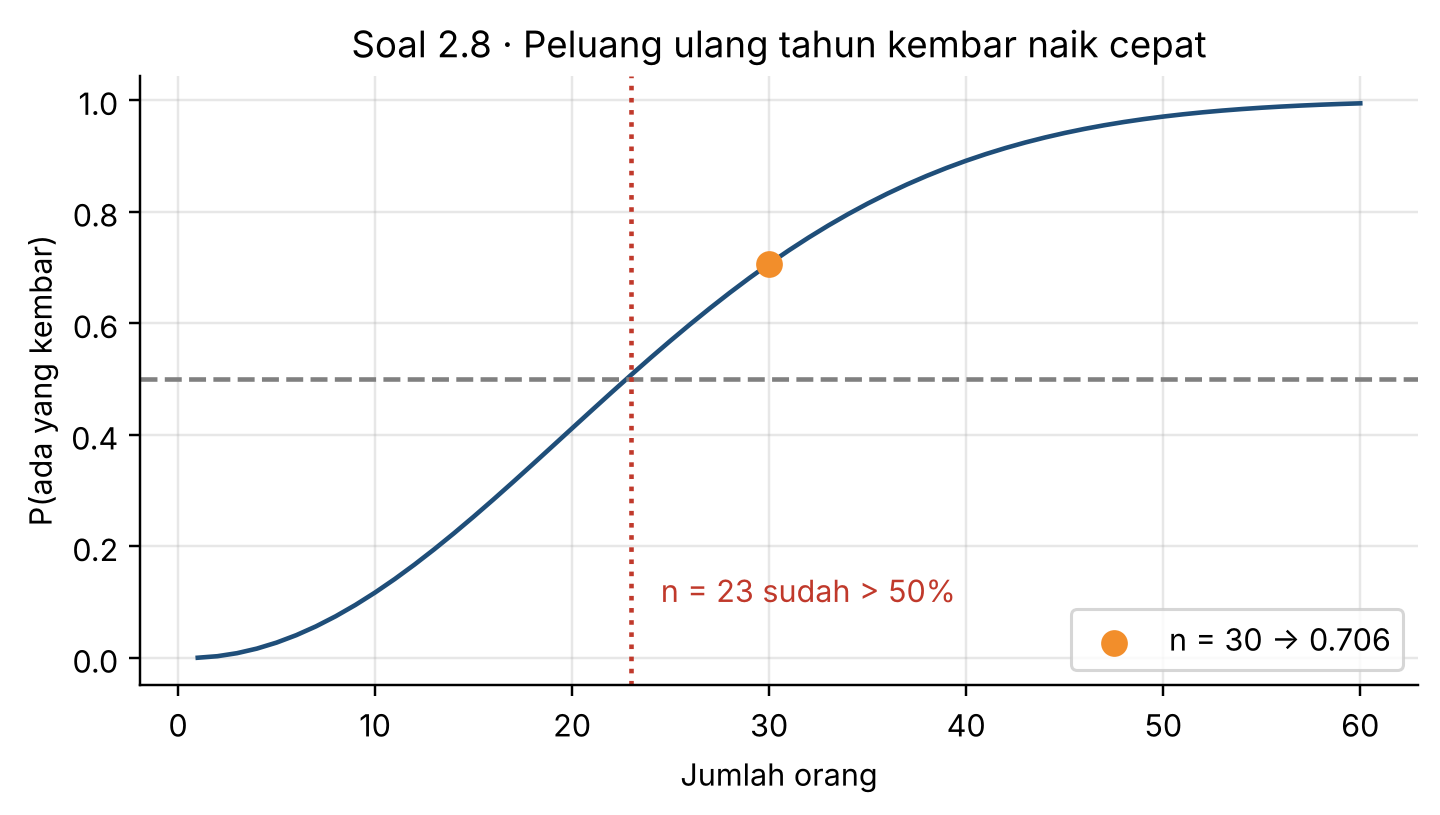

In [10]:
# ===== SOAL 2.8 · Simulasi: ulang tahun kembar di kelas 30 orang =====
n = 30
p_beda = 1.0                                   # manual: 365/365 x 364/365 x ... x 336/365
for i in range(n):
    p_beda *= (365 - i) / 365
manual = 1 - p_beda
p_python = 1 - math.perm(365, n) / 365**n      # permutasi: susunan tanggal yang semuanya beda

rng = np.random.default_rng(SEED)
tgl = np.sort(rng.integers(0, 365, size=(N_SIM, n)), axis=1)
ada_kembar = (np.diff(tgl, axis=1) == 0).any(axis=1)     # ada 2 tanggal sama berdampingan?
kotak_hasil("SOAL 2.8 · Ulang tahun kembar (n = 30)",
            [("P(ada yang kembar)", manual, p_python, ada_kembar.mean())],
            catatan="Mirip 'tabrakan hash': ID acak bisa bentrok jauh lebih cepat dari dugaan.")

ukuran = list(range(1, 61))     # int Python biasa; kalau np.arange, 365**k overflow (int64)
plt.plot(ukuran, [1 - math.perm(365, k) / 365**k for k in ukuran], color=BIRU)
plt.axhline(0.5, ls="--", color="gray"); plt.axvline(23, ls=":", color=MERAH)
plt.scatter([n], [p_python], color=ORANYE, zorder=3, s=60, label=f"n = 30 → {p_python:.3f}")
plt.text(24.5, 0.1, "n = 23 sudah > 50%", color=MERAH)
plt.xlabel("Jumlah orang"); plt.ylabel("P(ada yang kembar)"); plt.legend(loc="lower right")
plt.title("Soal 2.8 · Peluang ulang tahun kembar naik cepat"); plt.show()

**Soal 2.9** Setiap paket data hilang dengan peluang 0,02. Simulasikan 20.000 paket dan amati frekuensi relatif paket hilang dibanding peluang teoretisnya.

*Function:* `rng.random`, `np.cumsum`, `plt.plot`, `plt.xscale`

setelah     50 paket →    0 hilang → frekuensi relatif = 0.0000
setelah    500 paket →    9 hilang → frekuensi relatif = 0.0180
setelah   5000 paket →   96 hilang → frekuensi relatif = 0.0192
setelah  20000 paket →  410 hilang → frekuensi relatif = 0.0205
╔══ SOAL 2.9 · Frekuensi relatif paket hilang ════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(hilang), n = 20000        0.0200    0.0200    0.0205  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ Makin banyak paket diamati, frekuensi relatif makin dekat ke 0.02.


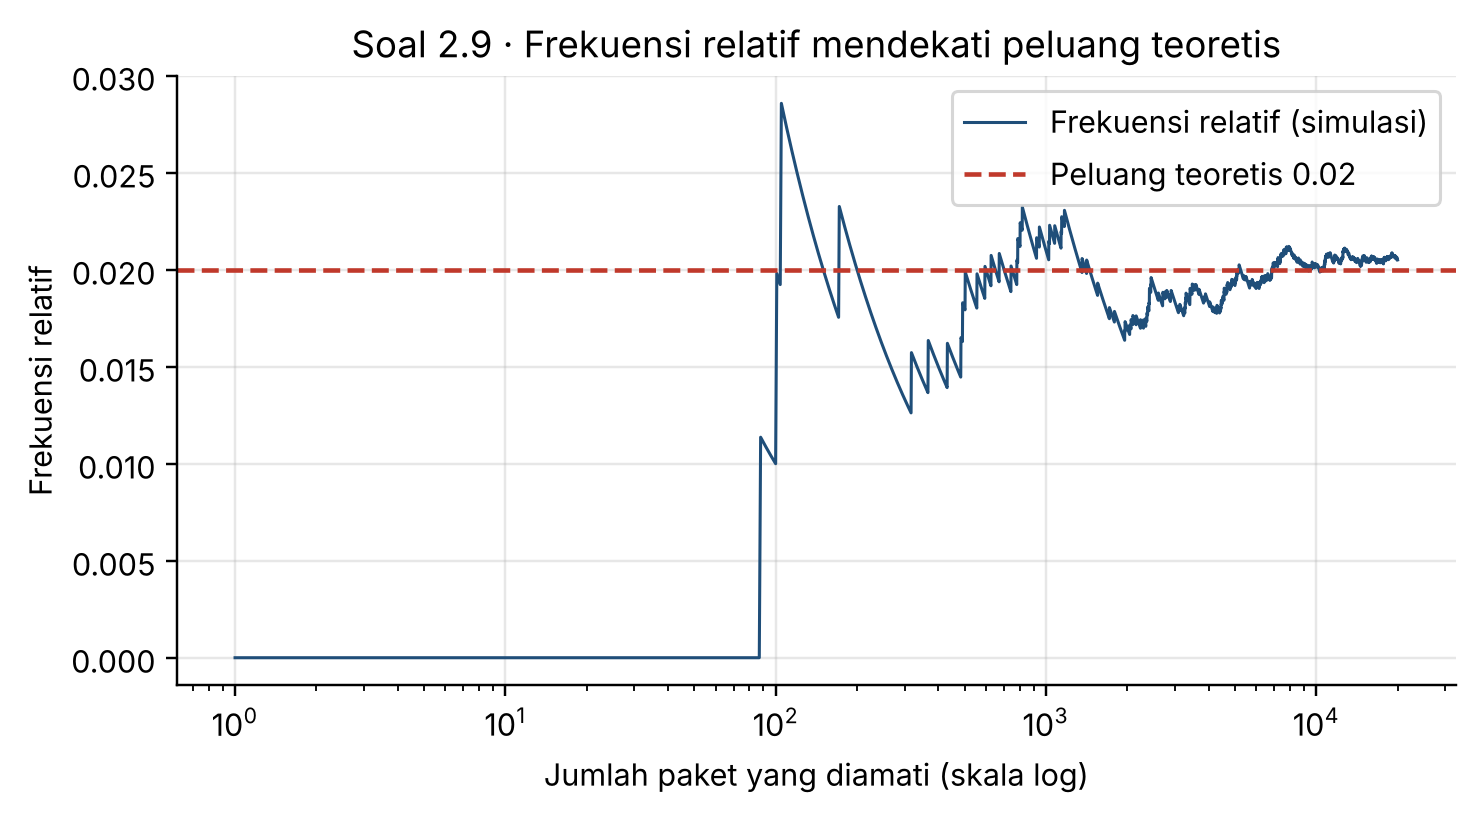

In [11]:
# ===== SOAL 2.9 · Probabilitas empiris (frekuensi relatif) paket hilang =====
p_hilang = 0.02
rng = np.random.default_rng(SEED)
hilang = rng.random(20_000) < p_hilang                    # True = paket hilang
frek = np.cumsum(hilang) / np.arange(1, hilang.size + 1)   # frekuensi relatif berjalan

for n in [50, 500, 5_000, 20_000]:
    print(f"setelah {n:>6} paket → {hilang[:n].sum():>4} hilang → frekuensi relatif = {frek[n - 1]:.4f}")
kotak_hasil("SOAL 2.9 · Frekuensi relatif paket hilang",
            [("P(hilang), n = 20000", p_hilang, p_hilang, frek[-1])],
            catatan="Makin banyak paket diamati, frekuensi relatif makin dekat ke 0.02.")

plt.plot(np.arange(1, hilang.size + 1), frek, color=BIRU, lw=1, label="Frekuensi relatif (simulasi)")
plt.axhline(p_hilang, color=MERAH, ls="--", label="Peluang teoretis 0.02")
plt.xscale("log"); plt.xlabel("Jumlah paket yang diamati (skala log)"); plt.ylabel("Frekuensi relatif")
plt.title("Soal 2.9 · Frekuensi relatif mendekati peluang teoretis"); plt.legend(); plt.show()

**Soal 2.10 (data asli kelompok 4)** Dari 200 run eksperimen QUIC (HTTP/3) vs HTTP/2, didefinisikan kejadian T = unduhan dengan throughput ≥ 100 Mbps. Hitung peluang empiris dan bersyaratnya.

*Function:* `pd.read_excel`, `pd.crosstab`, `np.where`, `.mean()`

In [12]:
# ===== SOAL 2.10 · Data asli kelompok 4: QUIC (HTTP/3) vs HTTP/2 =====
data = pd.read_excel("3TIC_04_PerformaQUICvsHTTP2.xlsx", sheet_name="Data")
data["kelas_T"] = np.where(data["throughput"] >= 100, "≥100 Mbps", "<100 Mbps")
print(pd.crosstab(data["protokol"], data["kelas_T"], margins=True, margins_name="Total"), "\n")

T = data["throughput"] >= 100            # kejadian T
H3 = data["protokol"] == "HTTP/3"        # kejadian H3
kotak_hasil("SOAL 2.10 · Data QUIC: peluang empiris", [
    ("P(T)", 141 / 200, T.mean(), None),                 # angka manual dibaca dari tabel
    ("P(T | HTTP/2)", 41 / 100, T[~H3].mean(), None),
    ("P(T | HTTP/3)", 100 / 100, T[H3].mean(), None),
    ("P(HTTP/3 | T)", 100 / 141, H3[T].mean(), None)])

print(f"\nCek saling bebas: P(T ∩ H3) = {(T & H3).mean():.4f}  vs  P(T) x P(H3) = {T.mean() * H3.mean():.4f}")
print("→ Tidak sama, jadi kejadian T TIDAK saling bebas dengan protokol yang dipakai.")

kelas_T   <100 Mbps  ≥100 Mbps  Total
protokol                             
HTTP/2           59         41    100
HTTP/3            0        100    100
Total            59        141    200 

╔══ SOAL 2.10 · Data QUIC: peluang empiris ═══════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(T)                        0.7050    0.7050         -  ✓ cocok     ║
║ P(T | HTTP/2)               0.4100    0.4100         -  ✓ cocok     ║
║ P(T | HTTP/3)               1.0000    1.0000         -  ✓ cocok     ║
║ P(HTTP/3 | T)               0.7092    0.7092         -  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝

Cek saling bebas: P(T ∩ H3) = 0.5000  vs  P(T) x P(H3) = 0.3525
→ Tidak sama, jadi kejadian T TIDAK saling bebas dengan protokol yang dipakai.


## 3 · Implementasi Distribusi Probabilitas

**Soal 3.1 (Binomial)** 25 sensor IoT mengirim data; tiap sensor gagal kirim dengan peluang 0,06, saling bebas. X = jumlah sensor yang gagal kirim.

*Function:* `math.comb`, `stats.binom` (`pmf`, `cdf`, `sf`, `mean`, `var`), `rng.binomial`, `plt.bar`

╔══ SOAL 3.1 · Binomial (n = 25, p = 0.06) ═══════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(X = 0)                    0.2129    0.2129    0.2130  ✓ cocok     ║
║ P(X ≤ 2)                    0.8129    0.8129    0.8127  ✓ cocok     ║
║ P(X ≥ 3)                    0.1871    0.1871    0.1873  ✓ cocok     ║
║ E(X) = np                   1.5000    1.5000    1.5005  ✓ cocok     ║
║ Var(X) = np(1-p)            1.4100    1.4100    1.4105  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝


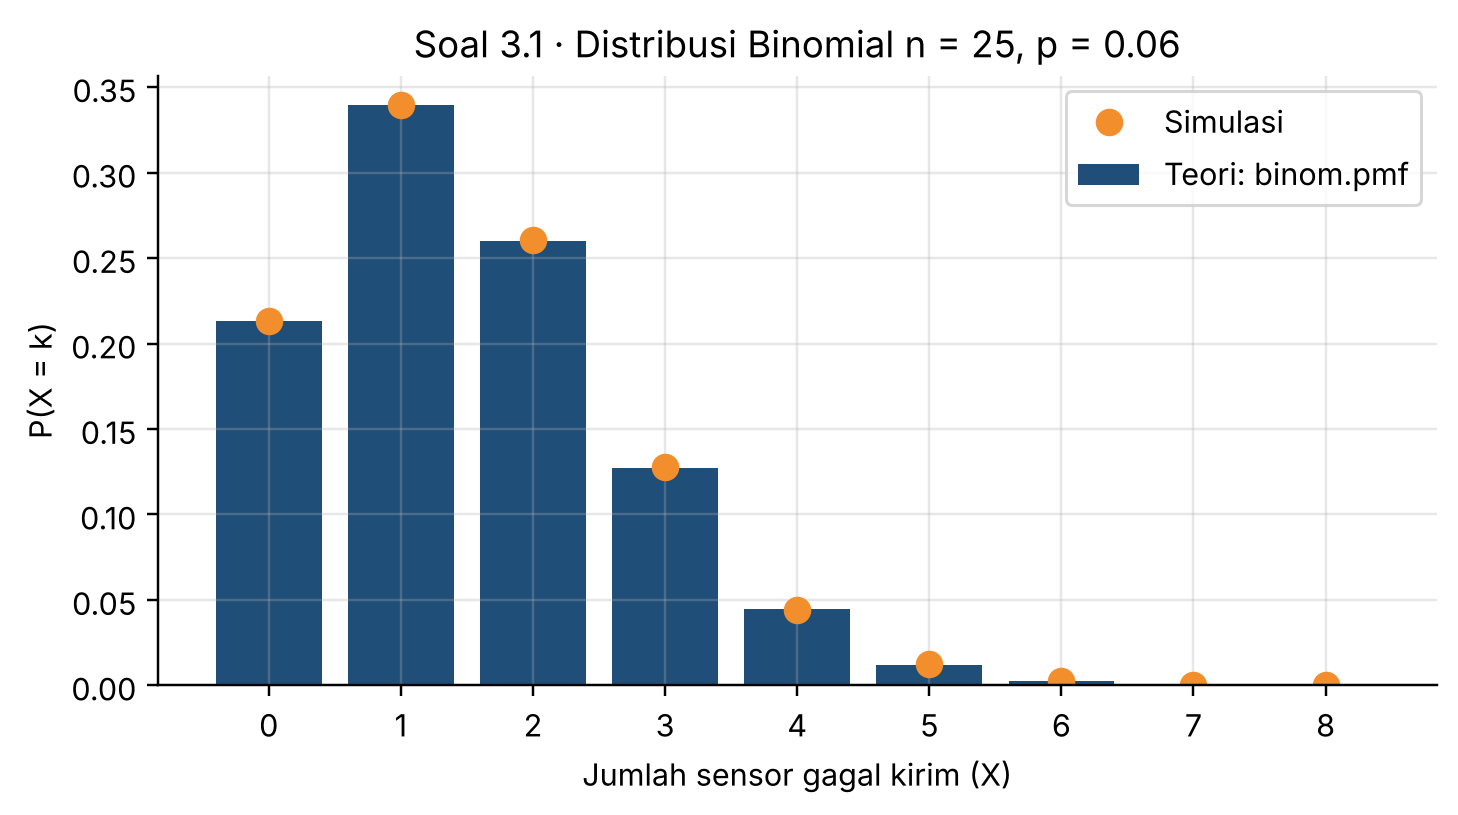

In [13]:
# ===== SOAL 3.1 · Binomial: sensor IoT gagal kirim data =====
n, p = 25, 0.06
X = stats.binom(n, p)
# Manual: P(X = k) = C(n,k) p^k (1-p)^(n-k)
manual_0 = math.comb(25, 0) * 0.06**0 * 0.94**25
manual_le2 = sum(math.comb(25, k) * 0.06**k * 0.94**(25 - k) for k in range(3))
rng = np.random.default_rng(SEED)
sim = rng.binomial(n, p, N_SIM)
kotak_hasil("SOAL 3.1 · Binomial (n = 25, p = 0.06)", [
    ("P(X = 0)", manual_0, X.pmf(0), (sim == 0).mean()),
    ("P(X ≤ 2)", manual_le2, X.cdf(2), (sim <= 2).mean()),
    ("P(X ≥ 3)", 1 - manual_le2, X.sf(2), (sim >= 3).mean()),
    ("E(X) = np", 25 * 0.06, X.mean(), sim.mean()),
    ("Var(X) = np(1-p)", 25 * 0.06 * 0.94, X.var(), sim.var())])

k = np.arange(0, 9)
plt.bar(k, X.pmf(k), color=BIRU, label="Teori: binom.pmf")
plt.plot(k, [(sim == i).mean() for i in k], "o", color=ORANYE, ms=8, label="Simulasi")
plt.xticks(k); plt.xlabel("Jumlah sensor gagal kirim (X)"); plt.ylabel("P(X = k)"); plt.legend()
plt.title("Soal 3.1 · Distribusi Binomial n = 25, p = 0.06"); plt.show()

**Soal 3.2 (Poisson)** Rata-rata ada 6 error per jam di log server. X = jumlah error dalam 1 jam. Alarm berbunyi bila X ≥ 11.

*Function:* `math.exp`, `math.factorial`, `stats.poisson` (`pmf`, `sf`, `mean`, `var`), `rng.poisson`, `plt.bar`

╔══ SOAL 3.2 · Poisson (λ = 6 error per jam) ═════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(X = 0)                    0.0025    0.0025    0.0025  ✓ cocok     ║
║ P(X = 6)                    0.1606    0.1606    0.1591  ✓ cocok     ║
║ P(X ≥ 11) → alarm           0.0426    0.0426    0.0418  ✓ cocok     ║
║ E(X) = λ                    6.0000    6.0000    5.9987  ✓ cocok     ║
║ Var(X) = λ                  6.0000    6.0000    5.9790  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ Alarm ≥ 11 error/jam tetap berbunyi di ±4.3% jam walau server normal.


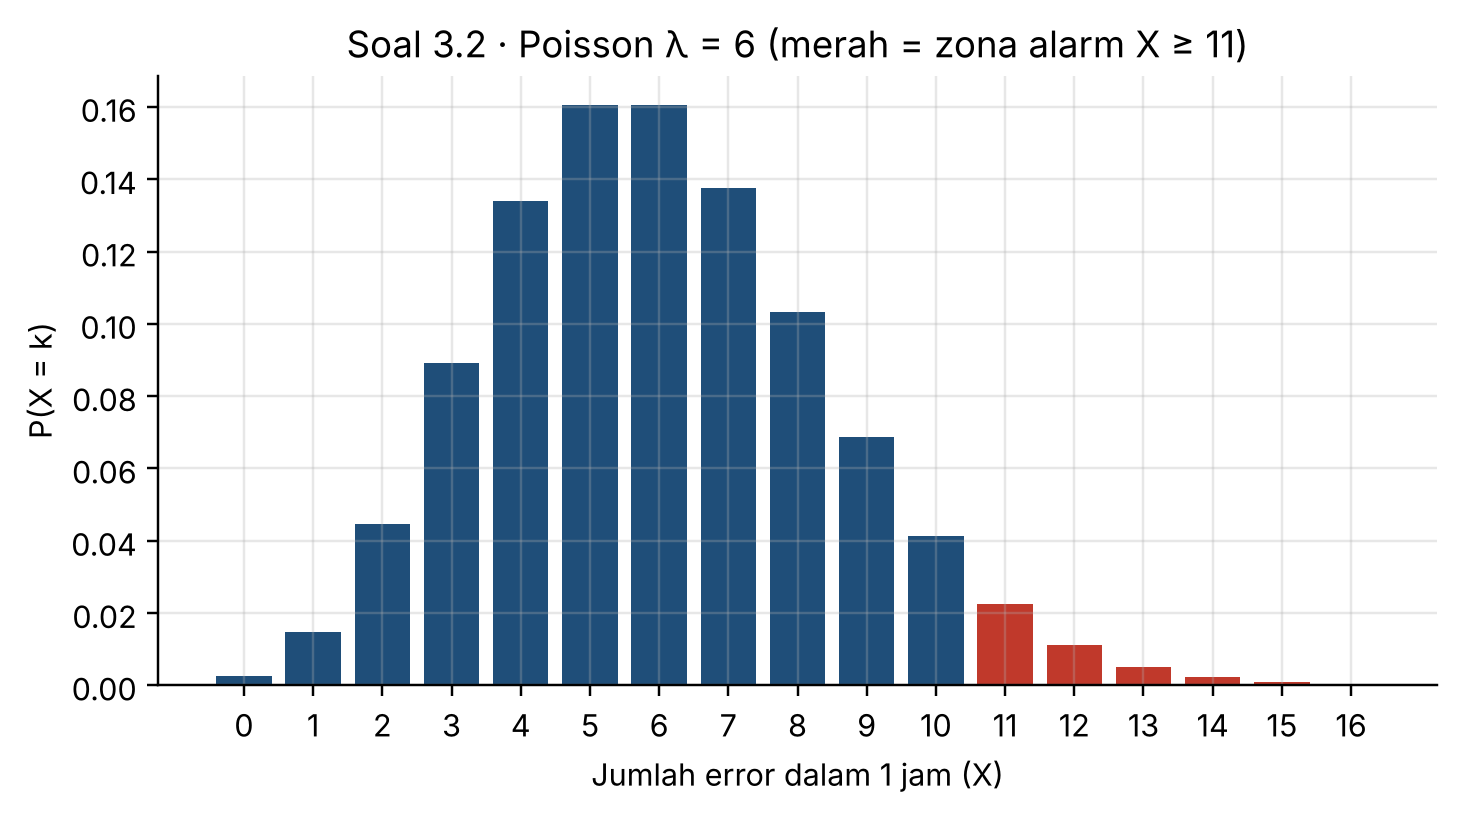

In [14]:
# ===== SOAL 3.2 · Poisson: jumlah error per jam di log server =====
lam = 6
X = stats.poisson(lam)
manual = lambda k: math.exp(-6) * 6**k / math.factorial(k)    # P(X=k) = e^-λ λ^k / k!
manual_ge11 = 1 - sum(manual(k) for k in range(11))
rng = np.random.default_rng(SEED)
sim = rng.poisson(lam, N_SIM)
kotak_hasil("SOAL 3.2 · Poisson (λ = 6 error per jam)", [
    ("P(X = 0)", manual(0), X.pmf(0), (sim == 0).mean()),
    ("P(X = 6)", manual(6), X.pmf(6), (sim == 6).mean()),
    ("P(X ≥ 11) → alarm", manual_ge11, X.sf(10), (sim >= 11).mean()),
    ("E(X) = λ", 6, X.mean(), sim.mean()),
    ("Var(X) = λ", 6, X.var(), sim.var())],
    catatan=f"Alarm ≥ 11 error/jam tetap berbunyi di ±{X.sf(10) * 100:.1f}% jam walau server normal.")

k = np.arange(0, 17)
plt.bar(k, X.pmf(k), color=[MERAH if i >= 11 else BIRU for i in k])
plt.xticks(k); plt.xlabel("Jumlah error dalam 1 jam (X)"); plt.ylabel("P(X = k)")
plt.title("Soal 3.2 · Poisson λ = 6 (merah = zona alarm X ≥ 11)"); plt.show()

**Soal 3.3 (Geometrik)** Tiap percobaan koneksi ke hotspot berhasil dengan peluang 0,25. X = percobaan ke berapa koneksi berhasil pertama kali.

*Function:* `stats.geom` (`pmf`, `cdf`, `sf`, `mean`, `var`), `rng.geometric`, `plt.bar`, `plt.axvline`

╔══ SOAL 3.3 · Geometrik (p = 0.25) ══════════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(X = 3)                    0.1406    0.1406    0.1403  ✓ cocok     ║
║ P(X ≤ 3)                    0.5781    0.5781    0.5781  ✓ cocok     ║
║ P(X > 5)                    0.2373    0.2373    0.2369  ✓ cocok     ║
║ E(X) = 1/p                  4.0000    4.0000    3.9960  ✓ cocok     ║
║ Var(X) = (1-p)/p²          12.0000   12.0000   12.0213  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝


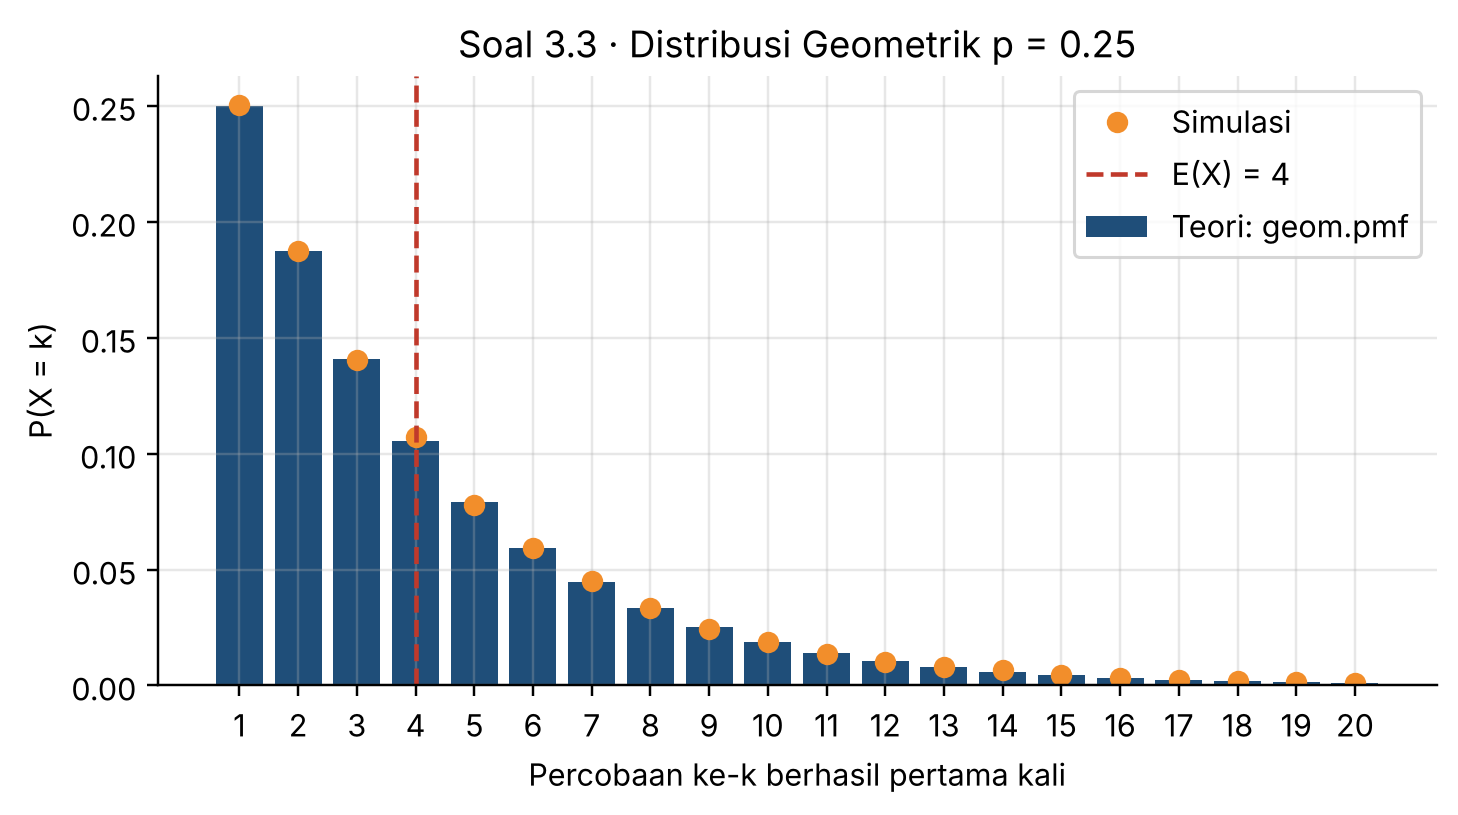

In [15]:
# ===== SOAL 3.3 · Geometrik: percobaan koneksi Wi-Fi sampai berhasil =====
p = 0.25
X = stats.geom(p)                             # X dimulai dari 1
# Manual: P(X = k) = (1-p)^(k-1) p
manual_3 = 0.75**2 * 0.25
manual_le3 = 1 - 0.75**3
manual_gt5 = 0.75**5                          # 5 percobaan pertama gagal semua
rng = np.random.default_rng(SEED)
sim = rng.geometric(p, N_SIM)
kotak_hasil("SOAL 3.3 · Geometrik (p = 0.25)", [
    ("P(X = 3)", manual_3, X.pmf(3), (sim == 3).mean()),
    ("P(X ≤ 3)", manual_le3, X.cdf(3), (sim <= 3).mean()),
    ("P(X > 5)", manual_gt5, X.sf(5), (sim > 5).mean()),
    ("E(X) = 1/p", 1 / 0.25, X.mean(), sim.mean()),
    ("Var(X) = (1-p)/p²", 0.75 / 0.25**2, X.var(), sim.var())])

k = np.arange(1, 21)
plt.bar(k, X.pmf(k), color=BIRU, label="Teori: geom.pmf")
plt.plot(k, [(sim == i).mean() for i in k], "o", color=ORANYE, label="Simulasi")
plt.axvline(X.mean(), ls="--", color=MERAH, label=f"E(X) = {X.mean():.0f}")
plt.xticks(k); plt.xlabel("Percobaan ke-k berhasil pertama kali"); plt.ylabel("P(X = k)"); plt.legend()
plt.title("Soal 3.3 · Distribusi Geometrik p = 0.25"); plt.show()

**Soal 3.4 (Hipergeometrik)** Satu kardus berisi 30 SSD, 4 di antaranya cacat. Teknisi mengambil 6 SSD acak tanpa pengembalian untuk dites. X = jumlah SSD cacat yang terambil.

*Function:* `math.comb`, `stats.hypergeom` (`pmf`, `sf`, `mean`, `var`), `stats.binom` (pembanding), `rng.hypergeometric`, `plt.bar`

╔══ SOAL 3.4 · Hipergeometrik (30 SSD, 4 cacat) ══════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(X = 0)                    0.3877    0.3877    0.3892  ✓ cocok     ║
║ P(X = 1)                    0.4431    0.4431    0.4404  ✓ cocok     ║
║ P(X ≥ 1)                    0.6123    0.6123    0.6108  ✓ cocok     ║
║ E(X) = nK/N                 0.8000    0.8000    0.8005  ✓ cocok     ║
║ Var(X)                      0.5738    0.5738    0.5790  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝


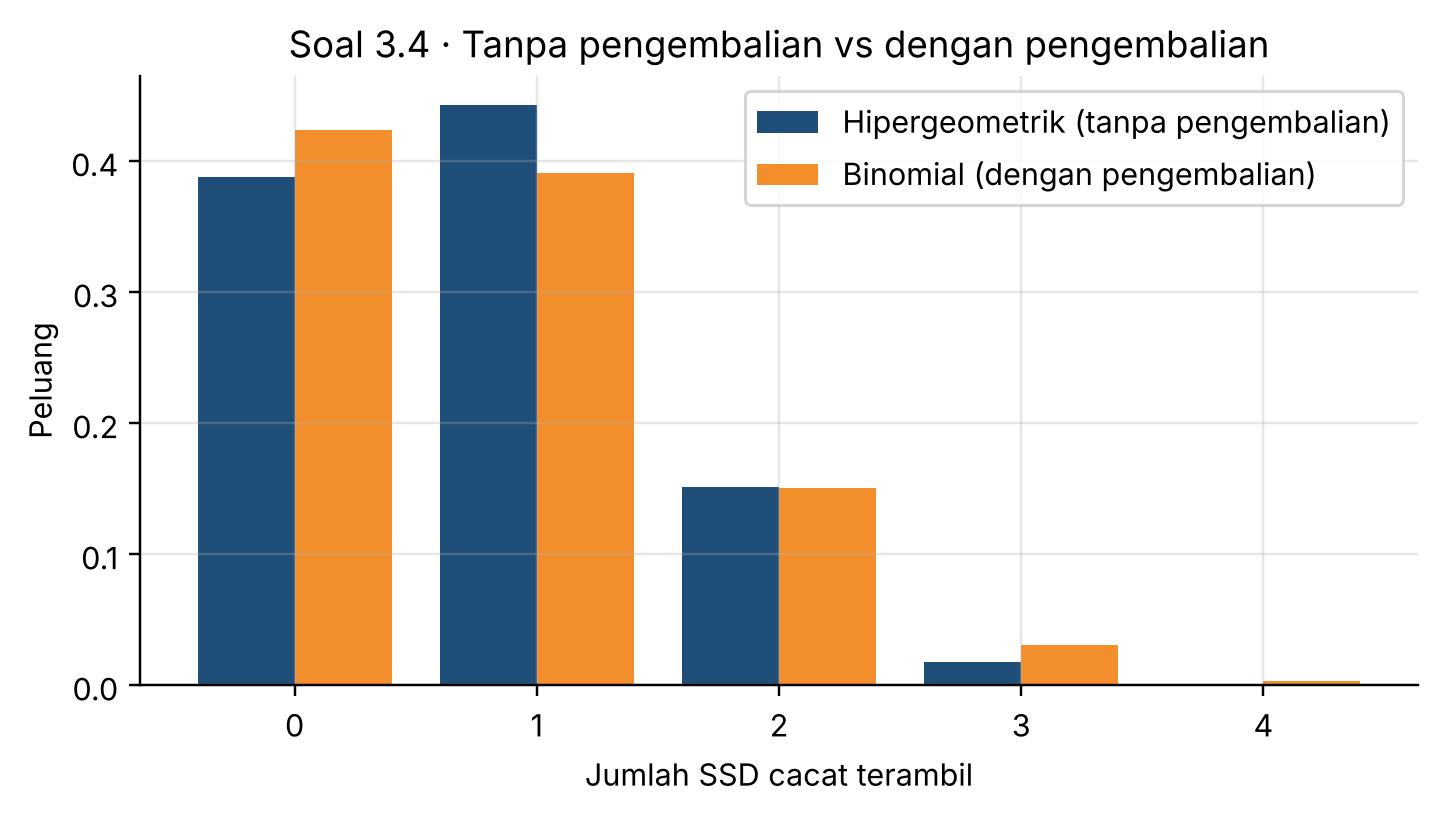

In [16]:
# ===== SOAL 3.4 · Hipergeometrik: SSD cacat, diambil tanpa pengembalian =====
N_total, K_cacat, n_ambil = 30, 4, 6
X = stats.hypergeom(M=N_total, n=K_cacat, N=n_ambil)   # urutan scipy: M total, n cacat, N diambil
manual = lambda k: math.comb(4, k) * math.comb(26, 6 - k) / math.comb(30, 6)
E_manual = 6 * 4 / 30
Var_manual = 6 * (4 / 30) * (26 / 30) * (30 - 6) / (30 - 1)
rng = np.random.default_rng(SEED)
sim = rng.hypergeometric(ngood=K_cacat, nbad=N_total - K_cacat, nsample=n_ambil, size=N_SIM)
kotak_hasil("SOAL 3.4 · Hipergeometrik (30 SSD, 4 cacat)", [
    ("P(X = 0)", manual(0), X.pmf(0), (sim == 0).mean()),
    ("P(X = 1)", manual(1), X.pmf(1), (sim == 1).mean()),
    ("P(X ≥ 1)", 1 - manual(0), X.sf(0), (sim >= 1).mean()),
    ("E(X) = nK/N", E_manual, X.mean(), sim.mean()),
    ("Var(X)", Var_manual, X.var(), sim.var())])

B = stats.binom(n_ambil, K_cacat / N_total)            # pembanding: kalau DIKEMBALIKAN
k = np.arange(0, 5)
plt.bar(k - 0.2, X.pmf(k), 0.4, color=BIRU, label="Hipergeometrik (tanpa pengembalian)")
plt.bar(k + 0.2, B.pmf(k), 0.4, color=ORANYE, label="Binomial (dengan pengembalian)")
plt.xticks(k); plt.xlabel("Jumlah SSD cacat terambil"); plt.ylabel("Peluang"); plt.legend()
plt.title("Soal 3.4 · Tanpa pengembalian vs dengan pengembalian"); plt.show()

**Soal 3.5 (Uniform kontinu)** Backup otomatis mulai di waktu acak antara 01.00 dan 03.00 (setiap menit sama mungkin). Maintenance dilakukan 01.00–01.30. X = menit mulai backup setelah 01.00.

*Function:* `stats.uniform` (`cdf`, `mean`, `var`, `std`, `pdf`), `rng.uniform`, `plt.hist`, `plt.fill_between`

╔══ SOAL 3.5 · Uniform U(0, 120) menit ═══════════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(X < 30) bentrok           0.2500    0.2500    0.2500  ✓ cocok     ║
║ P(45 < X < 75)              0.2500    0.2500    0.2490  ✓ cocok     ║
║ E(X) = (a+b)/2             60.0000   60.0000   59.9991  ✓ cocok     ║
║ Var(X) = (b-a)²/12         1200.00   1200.00   1201.18  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
→ Rata-rata backup mulai menit ke-60 (pukul 02.00), simpangan baku 34.6 menit.


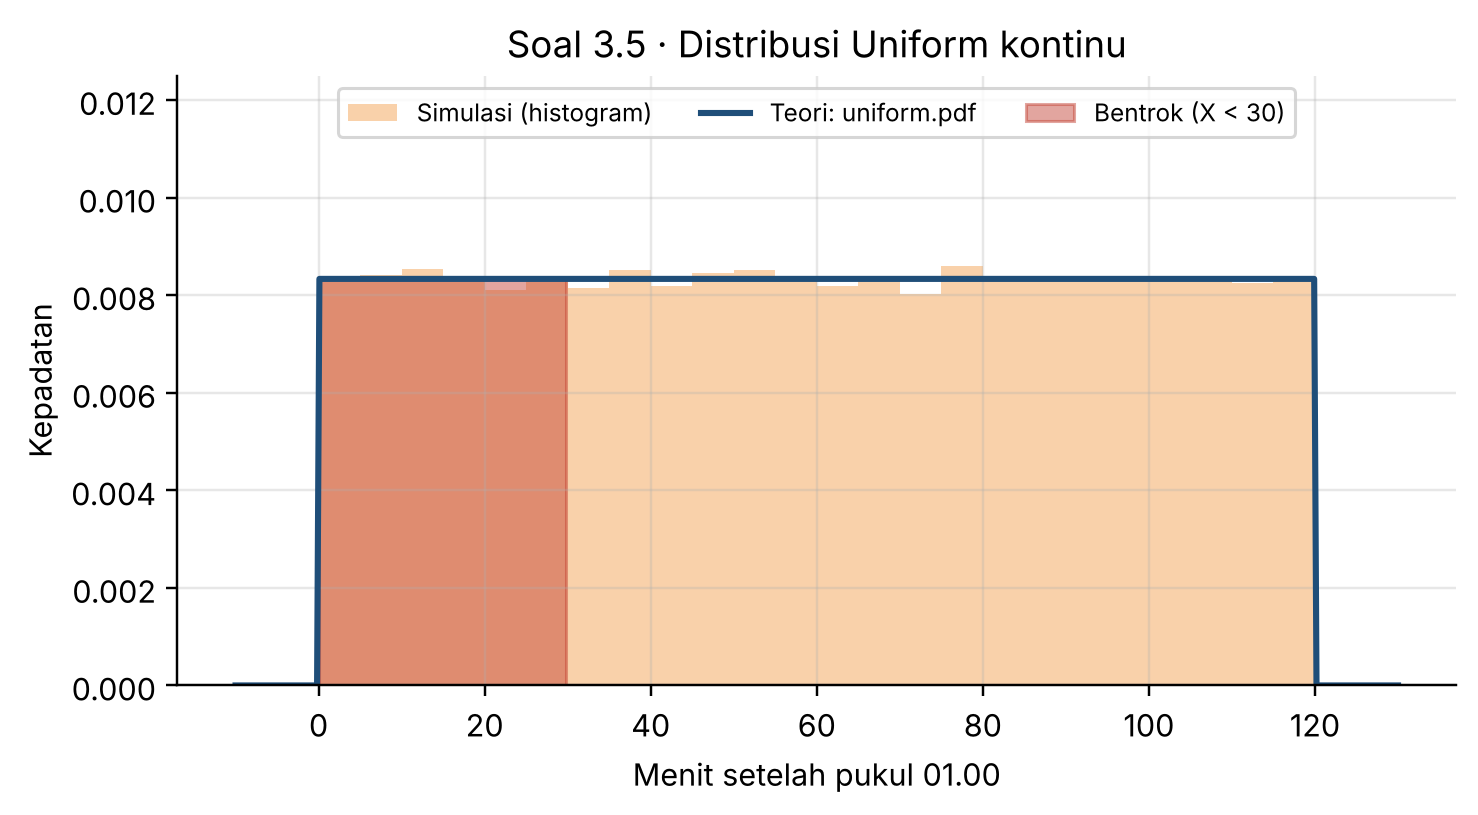

In [17]:
# ===== SOAL 3.5 · Uniform kontinu: jadwal backup acak 01.00-03.00 =====
a, b = 0, 120                               # menit setelah pukul 01.00
X = stats.uniform(loc=a, scale=b - a)        # scipy: loc = batas bawah, scale = lebar
# Manual: P(c < X < d) = (d - c) / (b - a)
manual_bentrok = (30 - 0) / 120              # bentrok dengan maintenance 01.00-01.30
manual_tengah = (75 - 45) / 120              # mulai antara 01.45 dan 02.15
rng = np.random.default_rng(SEED)
sim = rng.uniform(a, b, N_SIM)
kotak_hasil("SOAL 3.5 · Uniform U(0, 120) menit", [
    ("P(X < 30) bentrok", manual_bentrok, X.cdf(30), (sim < 30).mean()),
    ("P(45 < X < 75)", manual_tengah, X.cdf(75) - X.cdf(45), ((sim > 45) & (sim < 75)).mean()),
    ("E(X) = (a+b)/2", (0 + 120) / 2, X.mean(), sim.mean()),
    ("Var(X) = (b-a)²/12", 120**2 / 12, X.var(), sim.var())],
    catatan=f"Rata-rata backup mulai menit ke-60 (pukul 02.00), simpangan baku {X.std():.1f} menit.")

x = np.linspace(-10, 130, 500)
plt.hist(sim, bins=24, density=True, color=ORANYE, alpha=0.4, label="Simulasi (histogram)")
plt.plot(x, X.pdf(x), color=BIRU, lw=2, label="Teori: uniform.pdf")
plt.fill_between(x, X.pdf(x), where=(x >= 0) & (x <= 30), color=MERAH, alpha=0.45, label="Bentrok (X < 30)")
plt.ylim(0, 0.0125); plt.xlabel("Menit setelah pukul 01.00"); plt.ylabel("Kepadatan")
plt.legend(loc="upper center", ncol=3, fontsize=8); plt.title("Soal 3.5 · Distribusi Uniform kontinu"); plt.show()

**Soal 3.6 (Normal)** Waktu muat halaman web kampus berdistribusi normal dengan rata-rata 2,5 detik dan simpangan baku 0,5 detik.

*Function:* `math.erf`, `stats.norm` (`sf`, `cdf`, `ppf`, `mean`, `var`, `pdf`), `statistics.NormalDist` (`cdf`, `inv_cdf`), `rng.normal`, `np.percentile`

╔══ SOAL 3.6 · Normal (μ = 2.5 s, σ = 0.5 s) ═════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(X > 3.5) lambat           0.0228    0.0228    0.0221  ✓ cocok     ║
║ P(2 < X < 3)                0.6827    0.6827    0.6842  ✓ cocok     ║
║ Persentil 95% (detik)       3.3225    3.3224    3.3160  ✓ cocok     ║
║ E(X) = μ                    2.5000    2.5000    2.4995  ✓ cocok     ║
║ Var(X) = σ²                 0.2500    0.2500    0.2475  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
statistics.NormalDist → P(X > 3.5) = 0.0228 | persentil 95% = 3.3224
Cek kewajaran model: P(X < 0) = 2.9e-07 → waktu negatif praktis mustahil


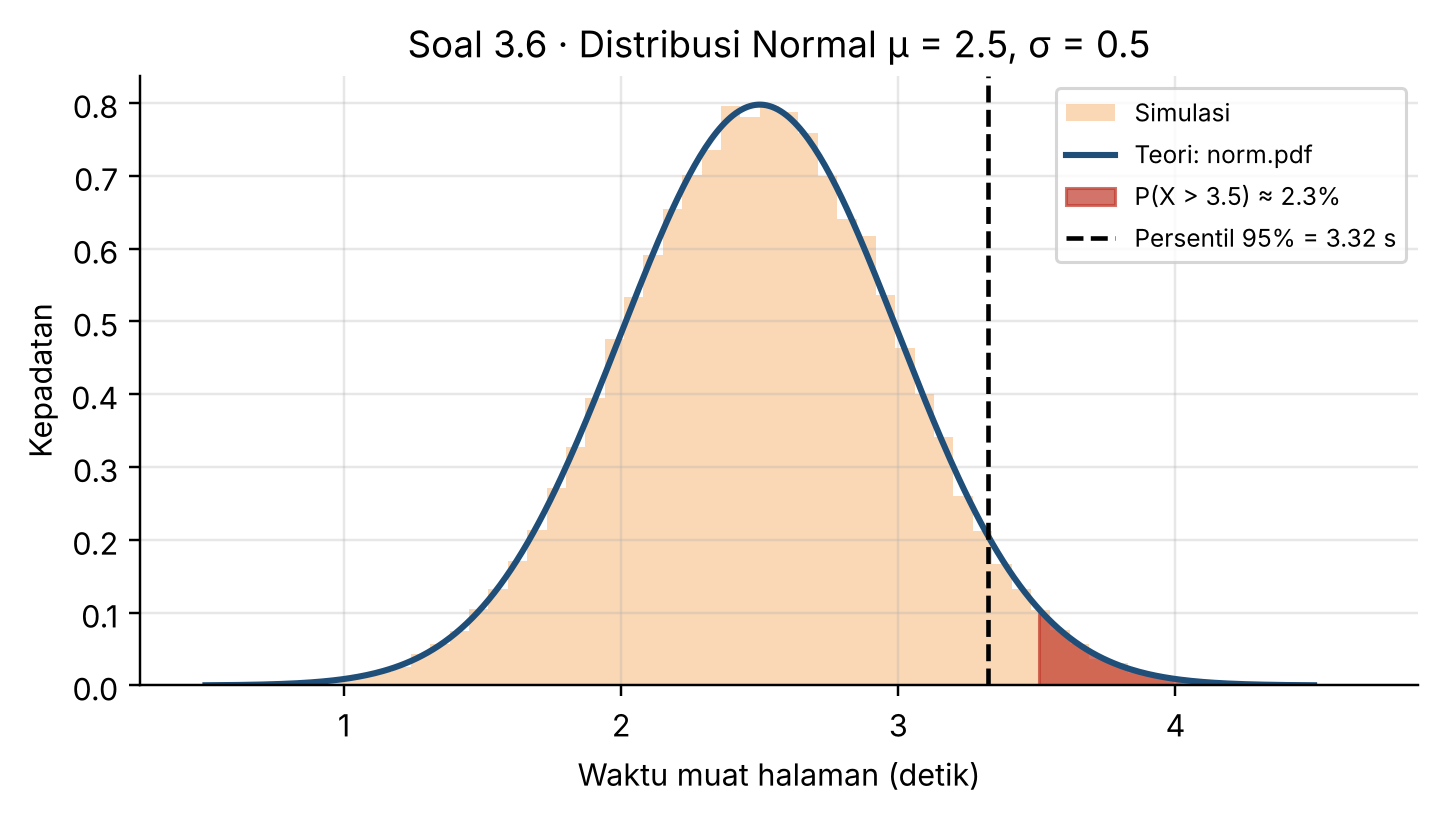

In [18]:
# ===== SOAL 3.6 · Normal: waktu muat halaman web kampus =====
mu, sigma = 2.5, 0.5
X = stats.norm(mu, sigma)
Phi = lambda z: 0.5 * (1 + math.erf(z / math.sqrt(2)))   # nilai tabel Z, ditulis sebagai rumus
# Manual: z = (x - μ) / σ, lalu baca Φ(z)
manual_lambat = 1 - Phi((3.5 - 2.5) / 0.5)                # z = 2
manual_wajar = Phi((3 - 2.5) / 0.5) - Phi((2 - 2.5) / 0.5)   # z = 1 dan z = -1
manual_p95 = 2.5 + 1.645 * 0.5                            # z tabel untuk 95% = 1.645
ND = statistics.NormalDist(mu, sigma)                     # pembanding dari library bawaan
rng = np.random.default_rng(SEED)
sim = rng.normal(mu, sigma, N_SIM)
kotak_hasil("SOAL 3.6 · Normal (μ = 2.5 s, σ = 0.5 s)", [
    ("P(X > 3.5) lambat", manual_lambat, X.sf(3.5), (sim > 3.5).mean()),
    ("P(2 < X < 3)", manual_wajar, X.cdf(3) - X.cdf(2), ((sim > 2) & (sim < 3)).mean()),
    ("Persentil 95% (detik)", manual_p95, X.ppf(0.95), np.percentile(sim, 95)),
    ("E(X) = μ", 2.5, X.mean(), sim.mean()),
    ("Var(X) = σ²", 0.25, X.var(), sim.var())])
print(f"statistics.NormalDist → P(X > 3.5) = {1 - ND.cdf(3.5):.4f} | persentil 95% = {ND.inv_cdf(0.95):.4f}")
print(f"Cek kewajaran model: P(X < 0) = {X.cdf(0):.1e} → waktu negatif praktis mustahil")

x = np.linspace(0.5, 4.5, 400)
plt.hist(sim, bins=60, density=True, color=ORANYE, alpha=0.35, label="Simulasi")
plt.plot(x, X.pdf(x), color=BIRU, lw=2, label="Teori: norm.pdf")
plt.fill_between(x, X.pdf(x), where=(x > 3.5), color=MERAH, alpha=0.7, label="P(X > 3.5) ≈ 2.3%")
plt.axvline(X.ppf(0.95), ls="--", color="black", label=f"Persentil 95% = {X.ppf(0.95):.2f} s")
plt.xlabel("Waktu muat halaman (detik)"); plt.ylabel("Kepadatan"); plt.legend(fontsize=8)
plt.title("Soal 3.6 · Distribusi Normal μ = 2.5, σ = 0.5"); plt.show()

**Soal 3.7 (Eksponensial)** Request datang ke server rata-rata 3 per detik. T = waktu antar-request (detik), T ~ Eksponensial dengan λ = 3.

*Function:* `math.exp`, `stats.expon` (`sf`, `cdf`, `mean`, `var`, `pdf`), `stats.poisson.pmf`, `rng.exponential`, `plt.hist`

╔══ SOAL 3.7 · Eksponensial (λ = 3 per detik) ════════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(T > 1 detik)              0.0498    0.0498    0.0495  ✓ cocok     ║
║ P(T < 0.2 detik)            0.4512    0.4512    0.4513  ✓ cocok     ║
║ E(T) = 1/λ                  0.3333    0.3333    0.3328  ✓ cocok     ║
║ Var(T) = 1/λ²               0.1111    0.1111    0.1113  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝
Cek hubungan dengan Poisson: poisson.pmf(0, 3) = 0.0498 = P(T > 1) = 0.0498


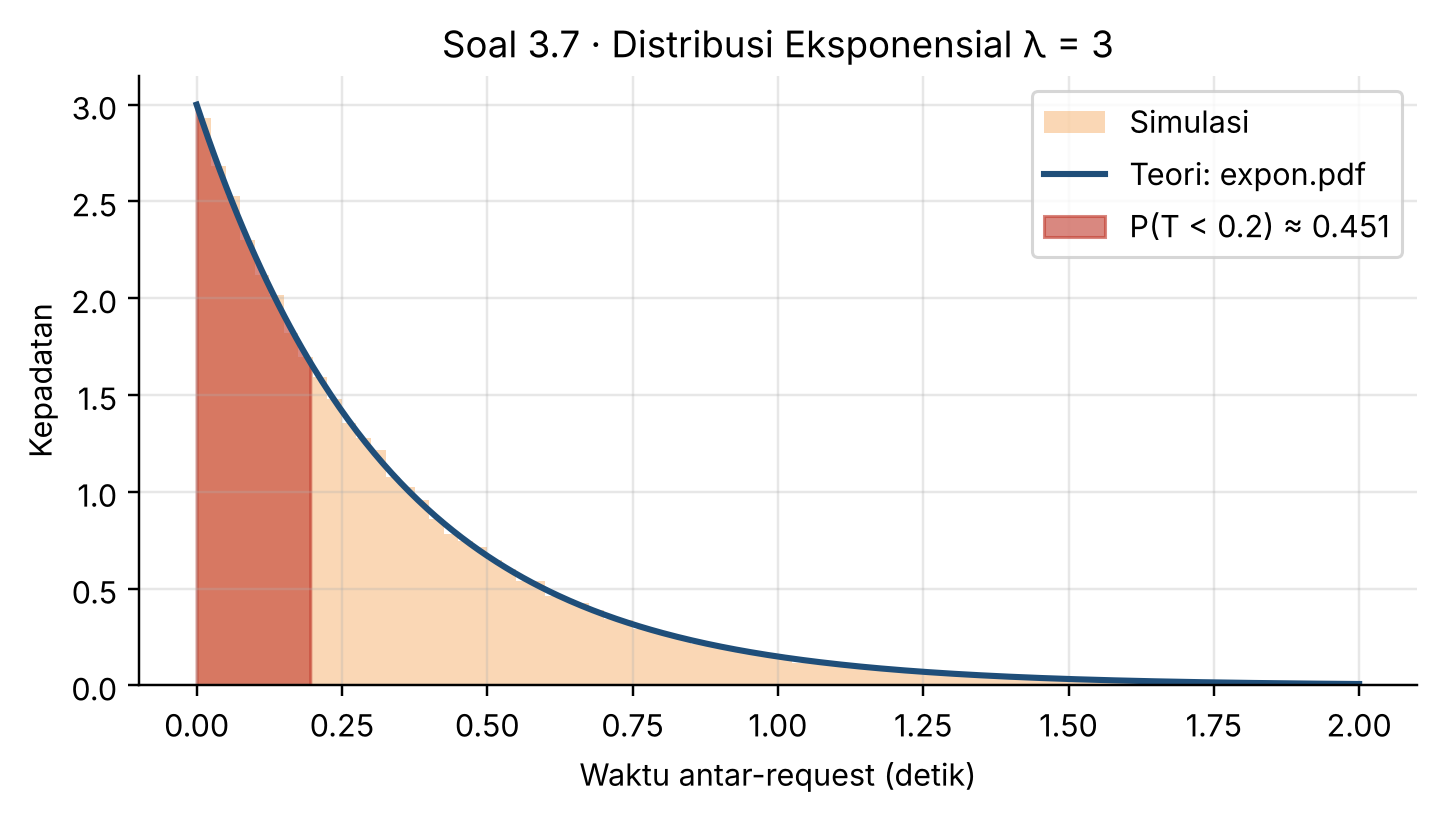

In [19]:
# ===== SOAL 3.7 · Eksponensial: waktu antar-request ke server =====
lam = 3
T = stats.expon(scale=1 / lam)                 # scipy memakai scale = 1/λ
# Manual: P(T > t) = e^(-λt) ; P(T < t) = 1 - e^(-λt)
manual_gt1 = math.exp(-3 * 1)
manual_lt02 = 1 - math.exp(-3 * 0.2)
rng = np.random.default_rng(SEED)
sim = rng.exponential(scale=1 / lam, size=N_SIM)
kotak_hasil("SOAL 3.7 · Eksponensial (λ = 3 per detik)", [
    ("P(T > 1 detik)", manual_gt1, T.sf(1), (sim > 1).mean()),
    ("P(T < 0.2 detik)", manual_lt02, T.cdf(0.2), (sim < 0.2).mean()),
    ("E(T) = 1/λ", 1 / 3, T.mean(), sim.mean()),
    ("Var(T) = 1/λ²", 1 / 9, T.var(), sim.var())])
print(f"Cek hubungan dengan Poisson: poisson.pmf(0, 3) = {stats.poisson.pmf(0, 3):.4f} = P(T > 1) = {T.sf(1):.4f}")

t = np.linspace(0, 2, 400)
plt.hist(sim, bins=80, range=(0, 2), density=True, color=ORANYE, alpha=0.35, label="Simulasi")
plt.plot(t, T.pdf(t), color=BIRU, lw=2, label="Teori: expon.pdf")
plt.fill_between(t, T.pdf(t), where=(t < 0.2), color=MERAH, alpha=0.6, label=f"P(T < 0.2) ≈ {T.cdf(0.2):.3f}")
plt.xlabel("Waktu antar-request (detik)"); plt.ylabel("Kepadatan"); plt.legend()
plt.title("Soal 3.7 · Distribusi Eksponensial λ = 3"); plt.show()

**Soal 3.8 (data asli kelompok 4)** Waktu respons HTTP/2 (100 run) dimodelkan dengan distribusi normal memakai rata-rata dan simpangan baku datanya. Bandingkan peluang dari model dengan proporsi data asli.

*Function:* `statistics.mean`, `statistics.stdev`, `stats.norm` (`sf`, `cdf`, `pdf`), `pd.DataFrame`, `plt.hist`

n = 100 | rata-rata = 63.600 ms | simpangan baku = 0.555 ms

╔══ SOAL 3.8 · Model Normal waktu respons HTTP/2 ═════════════════════╗
║ Besaran                     Manual    Python  Simulasi  Status      ║
╟─────────────────────────────────────────────────────────────────────╢
║ P(X > 64.5) model           0.0523    0.0523         -  ✓ cocok     ║
║ P(63 < X < 64) model        0.6248    0.6248         -  ✓ cocok     ║
╚═════════════════════════════════════════════════════════════════════╝

                 Peluang model  Proporsi data asli  Selisih
X > 64.5 ms            0.0523                0.04  -0.0123
63 < X < 64 ms         0.6248                0.59  -0.0348


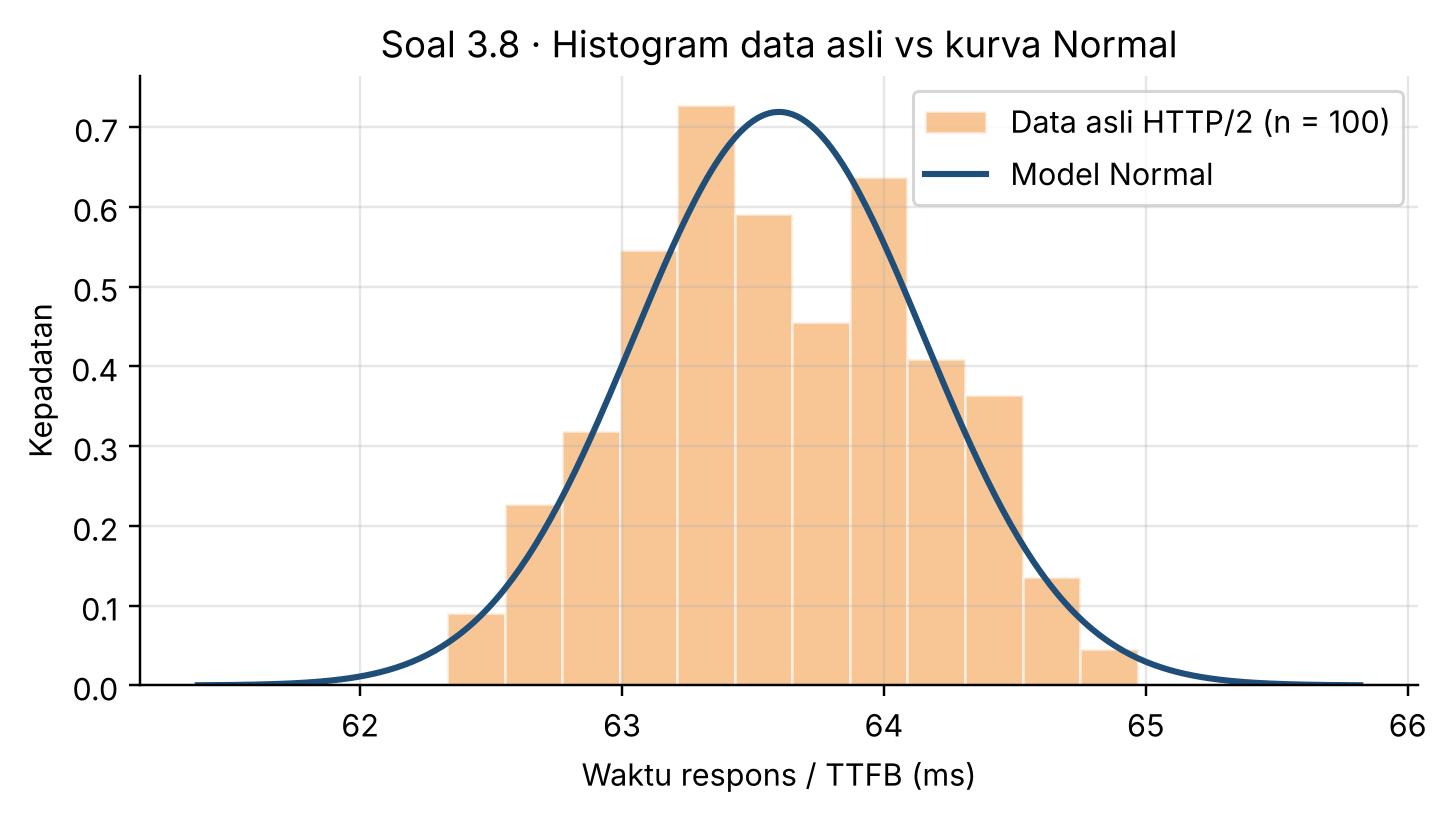

In [20]:
# ===== SOAL 3.8 · Data asli: model Normal untuk waktu respons HTTP/2 =====
h2 = data.loc[data["protokol"] == "HTTP/2", "waktu_respons"]      # 100 data, satuan ms
rata, sd = statistics.mean(h2), statistics.stdev(h2)
model = stats.norm(rata, sd)
print(f"n = {len(h2)} | rata-rata = {rata:.3f} ms | simpangan baku = {sd:.3f} ms\n")

kotak_hasil("SOAL 3.8 · Model Normal waktu respons HTTP/2", [      # Phi dari Soal 3.6
    ("P(X > 64.5) model", 1 - Phi((64.5 - rata) / sd), model.sf(64.5), None),
    ("P(63 < X < 64) model", Phi((64 - rata) / sd) - Phi((63 - rata) / sd), model.cdf(64) - model.cdf(63), None)])

banding = pd.DataFrame({
    "Peluang model": [model.sf(64.5), model.cdf(64) - model.cdf(63)],
    "Proporsi data asli": [(h2 > 64.5).mean(), ((h2 > 63) & (h2 < 64)).mean()]},
    index=["X > 64.5 ms", "63 < X < 64 ms"])
banding["Selisih"] = banding["Proporsi data asli"] - banding["Peluang model"]
print("\n", banding.round(4))

x = np.linspace(rata - 4 * sd, rata + 4 * sd, 300)
plt.hist(h2, bins=12, density=True, color=ORANYE, alpha=0.5, edgecolor="white", label="Data asli HTTP/2 (n = 100)")
plt.plot(x, model.pdf(x), color=BIRU, lw=2, label="Model Normal")
plt.xlabel("Waktu respons / TTFB (ms)"); plt.ylabel("Kepadatan"); plt.legend()
plt.title("Soal 3.8 · Histogram data asli vs kurva Normal"); plt.show()

## Rekap

In [21]:
# ===== REKAP: semua besaran yang dicek =====
rekap = pd.DataFrame(REKAP)
rekap["selisih_manual_python"] = (rekap["manual"] - rekap["python"]).abs()
ringkas = rekap.groupby("soal", sort=False).agg(
    dicek=("besaran", "size"),
    cocok=("status", lambda s: (s == "✓ cocok").sum()),
    selisih_maks=("selisih_manual_python", "max"))
print(ringkas.to_string(formatters={"selisih_maks": "{:.1e}".format}))
print(f"\nTOTAL: {len(rekap)} besaran dicek, {(rekap.status == '✓ cocok').sum()} cocok")

           dicek  cocok selisih_maks
soal                                
SOAL 2.1       1      1      0.0e+00
SOAL 2.2       2      2      0.0e+00
SOAL 2.3       2      2      0.0e+00
SOAL 2.4       2      2      1.1e-16
SOAL 2.5       3      3      1.1e-16
SOAL 2.6       2      2      0.0e+00
SOAL 2.7       2      2      0.0e+00
SOAL 2.8       1      1      2.2e-16
SOAL 2.9       1      1      0.0e+00
SOAL 2.10      4      4      0.0e+00
SOAL 3.1       5      5      1.3e-15
SOAL 3.2       5      5      5.6e-17
SOAL 3.3       5      5      5.6e-17
SOAL 3.4       5      5      0.0e+00
SOAL 3.5       4      4      0.0e+00
SOAL 3.6       5      5      7.3e-05
SOAL 3.7       4      4      0.0e+00
SOAL 3.8       2      2      1.1e-16

TOTAL: 55 besaran dicek, 55 cocok
